---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Kelompok G13 Brownbear

- Wafiq Hibban Robbany (13524016)
- Moh. Hafizh Irham Perdana (13524025)
- Wildan Abdurrahman Ghazali (13524054)
- A. Fawwaz Azam Wicaksono (13524070)
- Zahran Alvan Putra Winarko (13524124)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pemesanan yang dibatalkan meninggalkan kamar kosong yang sebenarnya masih bisa dijual ke tamu lain. Jika pembatalan dapat diprediksi lebih awal, penginapan dapat merencanakan *overbooking*, mengirim pengingat, dan menyesuaikan kebijakan pembatalan.

## Aim

Kami membangun model klasifikasi yang memprediksi `is_canceled` (1 = batal, 0 = tidak batal). KNN, Decision Tree Learning, Logistic Regression, SVM, dan Naive Bayes diimplementasikan dari awal, dibandingkan dengan pasangan scikit-learn, lalu model terbaik dipakai untuk submisi Kaggle.

## Metric

Metrik utama adalah macro F1, yaitu rata-rata F1 kelas batal dan kelas tidak batal. Kedua kelas berbobot sama, sehingga ambang keputusan (*threshold*) juga disetel agar kelas batal yang lebih sedikit tidak terabaikan.

## Dataset

Data training berisi 27.373 pemesanan dengan 17 fitur dan target `is_canceled`, sedangkan data test berisi 6.844 pemesanan tanpa label. Fitur mencakup jumlah tamu, lama menginap, paket makan, kategori kamar, kanal pemesanan, harga per malam, dan riwayat tamu. Delapan kolom memiliki nilai kosong, dan ID pemesanan dipertahankan sebagai teks.

## Approach

1. Data diperiksa terlebih dahulu, lalu data training dibagi menjadi training dan validasi tanpa memisahkan baris fitur yang identik.
2. Setiap pipeline hanya di-fit pada bagian training, lalu dipakai untuk mentransformasi validasi dan test.
3. Kelima model dibandingkan pada validasi yang sama, kemudian model terbaik ditingkatkan lewat rekayasa fitur, pencarian bobot fitur, dan pemilihan threshold dengan 5-fold cross-validation. Naive Bayes juga diperluas menjadi Tree-Augmented Naive Bayes agar ketergantungan antarfitur ikut dimodelkan.
4. Model akhir adalah KNN dengan jarak Manhattan berbobot ditambah penalti untuk atribut diskret yang berbeda. Pilihan ini didasarkan pada temuan bahwa banyak pemesanan memiliki "saudara" dengan label yang sama.
5. Model akhir dilatih ulang pada seluruh data training untuk submisi Kaggle.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import os
import pickle
import random
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Video, display
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

if (Path.cwd() / 'data/train.csv').is_file():
    os.chdir('src')
sys.path.insert(0, str(Path.cwd()))

from brownbear.models import (
    KNN, SVM, DecisionTree, LogisticRegression, NaiveBayes, TreeAugmentedNaiveBayes,
)
from brownbear.preprocessing import (
    BINARY_COLUMNS, CATEGORICAL_COLUMNS, DISCRETE_COLUMNS, FEATURE_COLUMNS, KNN_FEATURE_WEIGHTS,
    NUMERIC_COLUMNS, SIBLING_KEY, add_knn_features, impute_from_siblings, make_basic_preprocessor,
    make_discrete_preprocessor, make_knn_preprocessor, make_numeric_preprocessor,
    make_svm_preprocessor, make_tree_preprocessor, select_features, split_training_data,
)
from brownbear.visualization import (
    plot_bayesian_network, plot_decision_tree, plot_svm_kernels, save_loss_path_video,
)

## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED       = 42
    DATA_DIR   = Path('../data')
    OUTPUT_DIR = Path('../output')

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
description = pd.DataFrame({
    'dtype': train_df.dtypes.astype(str),
    'unique': train_df.nunique(dropna=True),
    'missing': train_df.isna().sum(),
})
print(description)
print(train_df[NUMERIC_COLUMNS].describe().T)

                            dtype  unique  missing
id                            str   27373        0
num_adults                float64       5      809
num_children              float64       6     3035
weekend_nights              int64       8        0
weekday_nights              int64      18        0
meal_package                  str       4     1760
needs_parking             float64       2     1082
room_category                 str       7     1002
days_before_arrival       float64     407     1123
arrival_year                int64       2        0
arrival_month               int64      12        0
arrival_day                 int64      31        0
booking_channel               str       5        0
is_returning_guest          int64       2        0
prior_cancellations         int64       9        0
prior_completed_bookings    int64      52        0
nightly_rate_idr          float64    2787     2038
special_requests          float64       6     2500
is_canceled                 int

## Explore Data

This part covers distributions and relationships between attributes.

In [7]:
print(train_df['is_canceled'].value_counts().sort_index().rename('count').to_frame())
for column in CATEGORICAL_COLUMNS:
    print(column, train_df[column].value_counts(dropna=False).to_dict())

lead_bins = pd.cut(train_df['days_before_arrival'], [-1, 7, 30, 90, 180, 500])
print(train_df.groupby(lead_bins, observed=True)['is_canceled'].agg(['size', 'mean']).round(3))
print(train_df.groupby('special_requests')['is_canceled'].agg(['size', 'mean']).round(3))

sibling_key = SIBLING_KEY + ['days_before_arrival', 'booking_channel', 'num_adults']
siblings = train_df.groupby(sibling_key)['is_canceled'].agg(['size', 'mean'])
shared = siblings[siblings['size'] > 1]
print('Pemesanan dalam kelompok saudara:', int(shared['size'].sum()))
print('Kelompok dengan label seragam:',
      round(shared.loc[shared['mean'].isin([0, 1]), 'size'].sum() / shared['size'].sum(), 3))
print('Data test yang punya saudara persis di training:',
      round(test_df[sibling_key].merge(siblings.reset_index(), on=sibling_key, how='left')['size'].notna().mean(), 3))

             count
is_canceled       
0            18404
1             8969
meal_package {'Breakfast': 19654, 'Room Only': 3713, 'Half Board': 2242, nan: 1760, 'Full Board': 4}
room_category {'Type B': 20447, 'Type G': 4396, nan: 1002, 'Type A': 699, 'Type D': 514, 'Type C': 189, 'Type F': 119, 'Type E': 7}
booking_channel {'Online Travel Agent': 17511, 'Offline Agent': 7960, 'Corporate': 1513, 'Complimentary': 301, 'Airline': 88}
                     size   mean
days_before_arrival             
(-1, 7]              4116  0.096
(7, 30]              4868  0.183
(30, 90]             7847  0.253
(90, 180]            5573  0.451
(180, 500]           3846  0.736
                   size   mean
special_requests              
0.0               12730  0.432
1.0                8334  0.238
2.0                3246  0.143
3.0                 496  0.000
4.0                  60  0.000
5.0                   7  0.000


Pemesanan dalam kelompok saudara: 5658
Kelompok dengan label seragam: 0.862
Data test yang punya saudara persis di training: 0.209


Pembatalan meningkat tajam seiring bertambahnya `days_before_arrival`, sedangkan pemesanan dengan permintaan khusus lebih jarang batal. Selain itu, banyak pemesanan memiliki "saudara", yaitu pemesanan lain dengan tanggal kedatangan, lama menginap, kanal, dan jumlah dewasa yang sama. Sekitar 86% kelompok saudara memiliki label seragam. `days_before_arrival` dan harga di antara saudara sering sedikit berbeda, sehingga pencocokan persis meremehkan jumlah saudara yang sebenarnya. Pola lokal ini menjadi alasan utama kami mengembangkan KNN.

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [8]:
raw_train = select_features(train_df)
raw_test = select_features(test_df)
quality = pd.DataFrame(index=FEATURE_COLUMNS)
quality['train_missing'] = raw_train.isna().sum()
quality['train_missing_pct'] = raw_train.isna().mean().mul(100)
quality['test_missing'] = raw_test.isna().sum()
quality['test_missing_pct'] = raw_test.isna().mean().mul(100)
print(quality.loc[quality[['train_missing', 'test_missing']].sum(axis=1) > 0].round(2))
print('Nilai dan tanggal kedatangan lolos validasi.')

                     train_missing  train_missing_pct  test_missing  \
num_adults                     809               2.96           180   
num_children                  3035              11.09           747   
days_before_arrival           1123               4.10           290   
nightly_rate_idr              2038               7.45           540   
special_requests              2500               9.13           593   
needs_parking                 1082               3.95           247   
meal_package                  1760               6.43           442   
room_category                 1002               3.66           242   

                     test_missing_pct  
num_adults                       2.63  
num_children                    10.91  
days_before_arrival              4.24  
nightly_rate_idr                 7.89  
special_requests                 8.66  
needs_parking                    3.61  
meal_package                     6.46  
room_category                    3.54  


Delapan fitur memiliki nilai kosong pada data latih dan data uji. Karena target tersedia hanya pada data latih, data uji disimpan khusus untuk submission.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [9]:
train_idx, val_idx = split_training_data(train_df, seed=CFG.SEED)
train_set, val_set = train_df.iloc[train_idx].copy(), train_df.iloc[val_idx].copy()
groups = raw_train.groupby(FEATURE_COLUMNS, dropna=False, sort=False).ngroup()
assert set(groups.iloc[train_idx]).isdisjoint(groups.iloc[val_idx])
assert sorted(np.r_[train_idx, val_idx]) == list(range(len(train_df)))
assert set(train_set['is_canceled']) == set(val_set['is_canceled']) == {0, 1}
split_summary = pd.DataFrame({
    name: {'rows': len(frame), 'canceled': int(frame['is_canceled'].sum()),
           'canceled_pct': frame['is_canceled'].mean() * 100}
    for name, frame in [('training', train_set), ('validation', val_set)]
}).T
print(split_summary.round(3))

               rows  canceled  canceled_pct
training    21899.0    7175.0        32.764
validation   5474.0    1794.0        32.773


Proporsi pembatalan hampir sama pada kedua bagian data. Pemisahan berdasarkan kelompok fitur juga mencegah baris yang identik berpindah ke validasi.

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [10]:
X_train_raw, X_val_raw = select_features(train_set), select_features(val_set)
y_train = train_set['is_canceled'].astype(int)
y_val = val_set['is_canceled'].astype(int)
test_ids = test_df['id'].copy()
assert not X_train_raw.isna().all().any(), 'Ada fitur yang seluruhnya kosong.'
print('Ketujuh belas fitur dipakai; ID dan target disimpan terpisah.')

Ketujuh belas fitur dipakai; ID dan target disimpan terpisah.


## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [11]:
prep = make_basic_preprocessor()
X_train = prep.fit_transform(X_train_raw)
X_val = prep.transform(X_val_raw)
X_test = prep.transform(raw_test)
imputer = prep.named_steps['impute']
fills = pd.DataFrame({'feature': NUMERIC_COLUMNS + BINARY_COLUMNS,
                     'strategy': ['median'] * len(NUMERIC_COLUMNS) + ['mode'] * len(BINARY_COLUMNS),
                     'value': np.r_[imputer.named_transformers_['numeric'].statistics_,
                                    imputer.named_transformers_['binary'].statistics_]})
print(fills)
print('Nilai kosong setelah preprocessing:', {name: int(frame.isna().sum().sum())
      for name, frame in [('train', X_train), ('validation', X_val), ('test', X_test)]})

rng = np.random.default_rng(CFG.SEED)
known_lead = X_train_raw.index[X_train_raw['days_before_arrival'].notna()]
hidden = rng.choice(known_lead, 1000, replace=False)
probe = X_train_raw.loc[hidden].assign(days_before_arrival=np.nan)
truth = X_train_raw.loc[hidden, 'days_before_arrival']
sibling_guess = impute_from_siblings(X_train_raw.drop(hidden), probe)
median_guess = X_train_raw.drop(hidden)['days_before_arrival'].median()
print('MAE imputasi days_before_arrival dari saudara:', round((sibling_guess - truth).abs().mean(), 1), 'hari')
print('MAE imputasi days_before_arrival dari median :', round((median_guess - truth).abs().mean(), 1), 'hari')

                     feature strategy      value
0                 num_adults   median        2.0
1               num_children   median        0.0
2             weekend_nights   median        1.0
3             weekday_nights   median        2.0
4        days_before_arrival   median       58.0
5               arrival_year   median     2024.0
6              arrival_month   median        8.0
7                arrival_day   median       16.0
8        prior_cancellations   median        0.0
9   prior_completed_bookings   median        0.0
10          nightly_rate_idr   median  1648000.0
11          special_requests   median        0.0
12             needs_parking     mode        0.0
13        is_returning_guest     mode        0.0
Nilai kosong setelah preprocessing: {'train': 0, 'validation': 0, 'test': 0}


MAE imputasi days_before_arrival dari saudara: 29.9 hari
MAE imputasi days_before_arrival dari median : 61.6 hari


Nilai numerik diisi dengan median, sedangkan penanda biner diisi dengan modus. Kategori yang kosong diberi label khusus agar tetap dapat dibedakan. Semua nilai pengganti dihitung dari data training saja.

Khusus untuk KNN, `days_before_arrival` yang kosong diisi dari pemesanan saudara paling mirip di data training, yaitu pemesanan dengan tanggal kedatangan dan lama menginap yang sama. Uji dengan 1.000 nilai yang sengaja disembunyikan menunjukkan galat imputasi ini sekitar setengah dari galat imputasi median. Pada penalti jarak KNN, nilai kosong tidak dianggap berbeda sehingga baris tersebut tidak dihukum dua kali.

### Duplicates

This part covers repeated records.

In [12]:
duplicate_summary = {
    'repeated_ids_train': int(train_df['id'].duplicated().sum()),
    'repeated_records_excluding_id': int(train_df.drop(columns='id').duplicated().sum()),
    'repeated_feature_rows': int(raw_train.duplicated().sum()),
    'conflicting_feature_groups': int(train_df.groupby(
        FEATURE_COLUMNS, dropna=False)['is_canceled'].nunique().gt(1).sum()),
    'shared_raw_groups_train_val': len(set(groups.iloc[train_idx]) & set(groups.iloc[val_idx])),
}
print(duplicate_summary)
print('Baris fitur yang berulang tetap disimpan sebagai pemesanan terpisah.')

{'repeated_ids_train': 0, 'repeated_records_excluding_id': 64, 'repeated_feature_rows': 66, 'conflicting_feature_groups': 2, 'shared_raw_groups_train_val': 0}
Baris fitur yang berulang tetap disimpan sebagai pemesanan terpisah.


Semua ID pemesanan berbeda, tetapi beberapa baris fitur memang berulang. Baris tersebut tetap disimpan karena dua kelompok fitur bahkan memiliki label yang berbeda.

### Outliers

This part covers values far from the rest of the data.

                             median         p99        max    skew       iqr  \
num_adults                      2.0        3.00        4.0  -0.312       0.0   
num_children                    0.0        2.00       10.0   4.902       0.0   
weekend_nights                  1.0        2.02        7.0   0.763       2.0   
weekday_nights                  2.0        6.00       17.0   1.685       2.0   
days_before_arrival            58.0      345.00      448.0   1.302     110.0   
arrival_year                 2024.0     2024.00     2024.0  -1.662       0.0   
arrival_month                   8.0       12.00       12.0  -0.349       5.0   
arrival_day                    16.0       31.00       31.0   0.036      15.0   
prior_cancellations             0.0        0.00       13.0  26.059       0.0   
prior_completed_bookings        0.0        4.00       58.0  20.416       0.0   
nightly_rate_idr          1648000.0  3456350.00  6338000.0   0.587  683000.0   
special_requests                0.0     

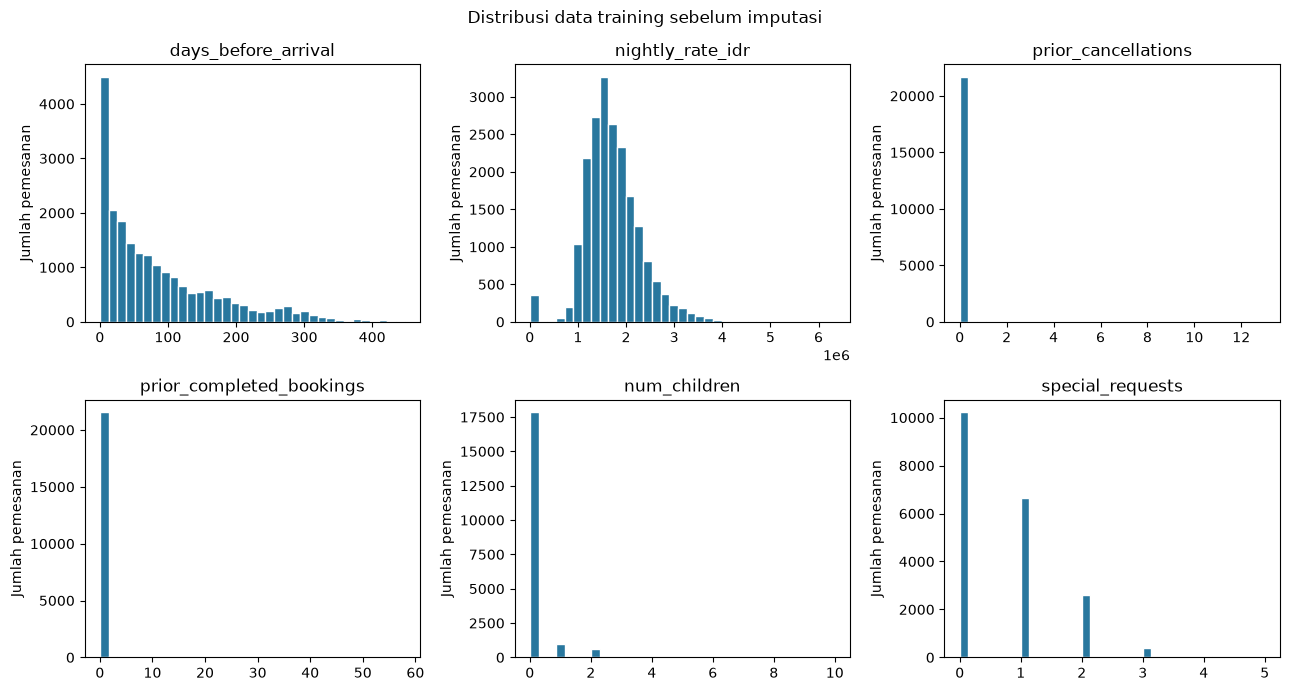

In [13]:
numeric = X_train_raw[NUMERIC_COLUMNS]
q1, q3 = numeric.quantile(.25), numeric.quantile(.75)
iqr = q3 - q1
outlier_review = pd.DataFrame({'median': numeric.median(), 'p99': numeric.quantile(.99),
                              'max': numeric.max(), 'skew': numeric.skew(), 'iqr': iqr,
                              'zero_pct': numeric.eq(0).sum() / numeric.notna().sum() * 100,
                              'outside_iqr': ((numeric < q1 - 1.5 * iqr) |
                                              (numeric > q3 + 1.5 * iqr)).sum()})
print(outlier_review.round(3))
plot_columns = ['days_before_arrival', 'nightly_rate_idr', 'prior_cancellations',
                'prior_completed_bookings', 'num_children', 'special_requests']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for column, ax in zip(plot_columns, axes.flat):
    ax.hist(numeric[column].dropna(), bins=35, color='#28779e', edgecolor='white')
    ax.set_title(column)
    ax.set_ylabel('Jumlah pemesanan')
fig.suptitle('Distribusi data training sebelum imputasi')
fig.tight_layout()
plt.show()

Aturan IQR menandai banyak nilai nol pada beberapa fitur hitungan. Nilai tersebut masih masuk akal, sehingga kami tidak menghapus baris hanya karena melewati batas IQR.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [14]:
audit_counts = {}
for name, frame in [('training', X_train_raw), ('validation', X_val_raw), ('test', raw_test)]:
    audit_counts[name] = {
        'zero_rate': int(frame['nightly_rate_idr'].eq(0).sum()),
        'zero_total_nights': int((frame['weekend_nights'] + frame['weekday_nights']).eq(0).sum()),
        'known_zero_total_guests': int((frame['num_adults'] + frame['num_children']).eq(0).sum()),
    }
print(pd.DataFrame(audit_counts).T)
print('Harga nol dan masa inap nol tetap dipertahankan.')

            zero_rate  zero_total_nights  known_zero_total_guests
training          330                 56                        0
validation         83                  8                        0
test               85                  9                        0
Harga nol dan masa inap nol tetap dipertahankan.


Harga nol dan masa inap nol ditemukan pada sebagian pemesanan. Nilai tersebut dipertahankan karena tidak ada bukti bahwa semuanya merupakan kesalahan pencatatan.

## Construct Data

Construction derives attributes and transforms values for modeling.

<!-- rubric v3: derived columns, rate_per_guest_night -->

### Attribute Construction

This part covers new attributes derived from existing ones.

In [15]:
knn_features = add_knn_features(X_train_raw)
derived_columns = ['month_sin', 'month_cos', 'log_lead', 'booking_ordinal', 'log_rate']
print(knn_features[derived_columns].describe().T.round(3))
booking_bins = pd.qcut(knn_features['booking_ordinal'], 5)
print(y_train.groupby(booking_bins, observed=True).mean().rename('canceled_rate').round(3))

                   count     mean      std   min      25%      50%      75%  \
month_sin        21899.0   -0.206    0.705  -1.0   -0.866   -0.500    0.500   
month_cos        21899.0   -0.036    0.677  -1.0   -0.500   -0.000    0.500   
log_lead         20998.0    3.729    1.486   0.0    2.890    4.078    4.852   
booking_ordinal  20998.0  422.914  146.343 -81.0  337.000  416.000  527.000   
log_rate         20254.0   14.092    1.843   0.0   14.109   14.315   14.521   

                     max  
month_sin          1.000  
month_cos          1.000  
log_lead           6.107  
booking_ordinal  727.000  
log_rate          15.662  
booking_ordinal
(-81.001, 296.0]    0.299
(296.0, 390.0]      0.400
(390.0, 454.0]      0.410
(454.0, 561.0]      0.338
(561.0, 727.0]      0.191
Name: canceled_rate, dtype: float64


Matriks dasar tetap memakai tujuh belas fitur asli. Untuk SVM dan KNN, kami menambahkan fitur turunan dari tanggal kedatangan, lama pemesanan, dan harga:

- `booking_ordinal` adalah tanggal pemesanan, yaitu tanggal kedatangan dikurangi `days_before_arrival`. Pemesanan rombongan biasanya dibuat pada hari yang sama, sehingga fitur ini membantu KNN menemukan pemesanan saudara.
- `month_sin` dan `month_cos` membuat bulan bersifat siklikal, sehingga Desember berdekatan dengan Januari.
- `log_lead` dan `log_rate` meredam kemiringan distribusi lama pemesanan dan harga.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [16]:
print(X_train[NUMERIC_COLUMNS + BINARY_COLUMNS].agg(['min', 'max']).T)

                             min        max
num_adults                   0.0        4.0
num_children                 0.0       10.0
weekend_nights               0.0        7.0
weekday_nights               0.0       17.0
days_before_arrival          0.0      448.0
arrival_year              2023.0     2024.0
arrival_month                1.0       12.0
arrival_day                  1.0       31.0
prior_cancellations          0.0       13.0
prior_completed_bookings     0.0       58.0
nightly_rate_idr             0.0  6338000.0
special_requests             0.0        5.0
needs_parking                0.0        1.0
is_returning_guest           0.0        1.0


Rentang harga jauh lebih besar daripada rentang fitur hitungan. Karena itu, pipeline numerik dan SVM melakukan standardisasi sebelum menghitung jarak atau margin.

### Encoding

This part covers the numeric representation of categorical attributes.

In [17]:
category_tables = []
for column in CATEGORICAL_COLUMNS:
    table = X_train.assign(is_canceled=y_train).groupby(column)['is_canceled'].agg(
        count='size', canceled_rate='mean').reset_index().rename(columns={column: 'category'})
    table.insert(0, 'feature', column)
    category_tables.append(table)
category_review = pd.concat(category_tables, ignore_index=True)
print(category_review.round(4))
unseen_categories = {column: {
    name: sorted(set(frame[column]) - set(X_train[column]))
    for name, frame in [('validation', X_val), ('test', X_test)]}
    for column in CATEGORICAL_COLUMNS}
print('Categories unseen during fitting:', unseen_categories)

            feature             category  count  canceled_rate
0      meal_package            Breakfast  15725         0.3124
1      meal_package           Full Board      4         0.2500
2      meal_package           Half Board   1793         0.4568
3      meal_package              MISSING   1404         0.3127
4      meal_package            Room Only   2973         0.3374
5     room_category              MISSING    797         0.3501
6     room_category               Type A    564         0.4255
7     room_category               Type B  16365         0.3218
8     room_category               Type C    161         0.2609
9     room_category               Type D    406         0.3325
10    room_category               Type E      6         0.1667
11    room_category               Type F     97         0.2577
12    room_category               Type G   3503         0.3389
13  booking_channel              Airline     72         0.3056
14  booking_channel        Complimentary    236        

Categories unseen during fitting: {'meal_package': {'validation': [], 'test': []}, 'room_category': {'validation': [], 'test': []}, 'booking_channel': {'validation': [], 'test': []}}


Kategori nominal diubah menjadi kolom one-hot untuk model numerik. Naive Bayes memakai kode kategori diskret, sedangkan pohon keputusan membaca kategori asli. KNN memakai keduanya: kolom one-hot ikut dihitung dalam jarak Manhattan, sedangkan kode kategori dipakai untuk penalti saat kategori dua pemesanan berbeda.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [18]:
corr = X_train[NUMERIC_COLUMNS + BINARY_COLUMNS].corr()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
correlation_review = pairs.rename('pearson_r').reset_index()
correlation_review.columns = ['feature_1', 'feature_2', 'pearson_r']
correlation_review = correlation_review.sort_values('pearson_r', key=lambda s: s.abs(), ascending=False)
print(correlation_review.head(10).round(4))
numeric_by_class = X_train.assign(is_canceled=y_train).groupby('is_canceled')[NUMERIC_COLUMNS].median().T
print(numeric_by_class)

dropped = [column for column in knn_features.columns if column not in KNN_FEATURE_WEIGHTS]
print(f'Fitur KNN yang dipakai: {len(KNN_FEATURE_WEIGHTS)} dari {knn_features.shape[1]}')
print('Fitur dengan bobot 0:', dropped)

                    feature_1                 feature_2  pearson_r
139  prior_completed_bookings        is_returning_guest     0.5388
121       prior_cancellations  prior_completed_bookings     0.4669
125       prior_cancellations        is_returning_guest     0.3841
76               arrival_year             arrival_month    -0.3427
24               num_children          nightly_rate_idr     0.3115
10                 num_adults          nightly_rate_idr     0.2897
31             weekend_nights            weekday_nights     0.1893
13                 num_adults        is_returning_guest    -0.1884
11                 num_adults          special_requests     0.1834
151          nightly_rate_idr          special_requests     0.1792
is_canceled                       0          1
num_adults                      2.0        2.0
num_children                    0.0        0.0
weekend_nights                  1.0        1.0
weekday_nights                  2.0        2.0
days_before_arrival         

Beberapa fitur saling berkorelasi, tetapi jumlah fitur hasil encoding masih kecil. Kami tidak memakai PCA karena PCA mencampur fitur dan merusak struktur pemesanan saudara yang dimanfaatkan KNN. Sebagai gantinya, setiap fitur KNN diberi bobot hasil pencarian pada 5-fold cross-validation (lihat bagian *Improvements*). Fitur yang bobotnya 0, misalnya sebagian kolom one-hot dan `num_children`, otomatis tidak dipakai dalam perhitungan jarak.

## Class Balance

This part covers the proportion of each class in the training data.

In [19]:
majority = int(y_train.mode().iloc[0])
baseline_pred = np.full(len(y_val), majority)
baseline = {'majority_class': majority,
            'validation_macro_f1': f1_score(y_val, baseline_pred, average='macro', labels=[0, 1], zero_division=0),
            'validation_accuracy': accuracy_score(y_val, baseline_pred)}
print(split_summary.round(3))
print(baseline)

               rows  canceled  canceled_pct
training    21899.0    7175.0        32.764
validation   5474.0    1794.0        32.773
{'majority_class': 0, 'validation_macro_f1': 0.4020100502512563, 'validation_accuracy': 0.6722689075630253}


Kelas tidak seimbang sempurna, sehingga akurasi saja kurang cukup untuk evaluasi. Macro F1 memberi bobot yang sama pada kedua kelas saat membandingkan model. Kami tidak melakukan *resampling* karena oversampling mengubah kepadatan tetangga pada KNN. Ketidakseimbangan ditangani dengan memilih threshold yang memaksimalkan macro F1.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [20]:
for clean, raw in [(X_train, X_train_raw), (X_val, X_val_raw), (X_test, raw_test)]:
    assert clean.shape == raw.shape
    assert clean.columns.tolist() == FEATURE_COLUMNS
    assert clean.index.equals(raw.index)
    assert not clean.isna().any().any()
    assert np.isfinite(clean[NUMERIC_COLUMNS + BINARY_COLUMNS].to_numpy()).all()
    for column in NUMERIC_COLUMNS + BINARY_COLUMNS:
        known = raw[column].notna()
        np.testing.assert_array_equal(clean.loc[known, column], raw.loc[known, column])
assert set(X_train.columns).isdisjoint({'id', 'is_canceled'})
print('Lolos: skema, urutan baris, nilai teramati, dan nilai kosong')

Lolos: skema, urutan baris, nilai teramati, dan nilai kosong


---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [21]:
numeric_prep = make_numeric_preprocessor().fit(train_set)
nb_prep = make_discrete_preprocessor(n_bins=5).fit(train_set)
knn_prep = make_knn_preprocessor().fit(train_set)
X_train_numeric, X_val_numeric = numeric_prep.transform(train_set), numeric_prep.transform(val_set)
X_train_nb, X_val_nb = nb_prep.transform(train_set), nb_prep.transform(val_set)
X_train_knn, X_val_knn = knn_prep.transform(train_set), knn_prep.transform(val_set)
assert X_train_numeric.shape[0] == X_train_nb.shape[0] == X_train_knn.shape[0] == len(train_set)
assert X_val_numeric.shape[0] == X_val_nb.shape[0] == X_val_knn.shape[0] == len(val_set)
assert np.isfinite(X_val_numeric).all() and (X_val_nb >= 0).all()
assert np.isfinite(X_val_knn[:, :len(knn_prep.columns_)]).all()
print('Basic:', X_train.shape, X_val.shape, X_test.shape)
print('Numeric:', X_train_numeric.shape, X_val_numeric.shape)
print('Categorical NB:', X_train_nb.shape, X_val_nb.shape)
print('KNN:', X_train_knn.shape, X_val_knn.shape)

Basic: (21899, 17) (5474, 17) (6844, 17)
Numeric: (21899, 32) (5474, 32)
Categorical NB: (21899, 17) (5474, 17)
KNN: (21899, 39) (5474, 39)


Pipeline menggabungkan tahap persiapan agar semua model menerima data yang sudah ditransformasi secara konsisten. Pipeline numerik, Naive Bayes, dan KNN di-fit pada training saja. Ketiganya menghasilkan format yang berbeda karena kebutuhan masukan setiap model memang berbeda.

Matriks KNN terdiri atas dua bagian. Bagian pertama berisi fitur yang telah diimputasi, distandardisasi, dan dikalikan bobotnya untuk jarak Manhattan. Bagian kedua berisi nilai mentah untuk penalti: tanggal kedatangan, jumlah malam, jumlah tamu, kamar, paket makan, permintaan khusus, parkir, `days_before_arrival`, dan log harga. Nilai kosong pada bagian kedua tetap NaN.

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

Perbandingan awal memakai lima ribu baris training yang dipilih secara stratifikasi. Seluruh baris validasi tetap dipakai agar penilaian setiap model konsisten. Setelah model dipilih, pelatihan akhir memakai seluruh data berlabel.

In [22]:
model_rows, _ = train_test_split(
    np.arange(len(train_set)), train_size=5000,
    stratify=y_train, random_state=CFG.SEED,
)
y_model = y_train.iloc[model_rows].to_numpy()
y_valid = y_val.to_numpy()
svm_prep = make_svm_preprocessor().fit(train_set)
model_inputs = {
    'numeric': (X_train_numeric[model_rows], X_val_numeric),
    'tree': (X_train_raw.iloc[model_rows], X_val_raw),
    'nb': (X_train_nb[model_rows], X_val_nb),
    'svm': (svm_prep.transform(train_set.iloc[model_rows]),
            svm_prep.transform(val_set)),
    'knn': (X_train_knn[model_rows], X_val_knn),
}
knn_params = dict(k=25, metric='manhattan', weights='distance', vote_power=1.5,
                  mismatch_groups=knn_prep.mismatch_groups_, tolerances=knn_prep.tolerances_)
logreg_params = {
    'LogReg L1': dict(penalty='l1', reg_strength=.01, max_iter=2000, tol=1e-5),
    'LogReg L2': dict(penalty='l2', reg_strength=.01, max_iter=2000, tol=1e-5),
    'LogReg Elastic Net': dict(penalty='elasticnet', reg_strength=.01, l1_ratio=.5, max_iter=2000, tol=1e-5),
}
svm_params = {
    'linear': dict(C=1, max_iter=100_000),
    'polynomial': dict(C=1, degree=3, gamma=.1, coef0=1, max_iter=100_000),
    'gaussian': dict(C=3, gamma=.1, class_weight={1: 1.3}, max_iter=100_000),
}
model_factories = {
    'KNN': ('knn', lambda: KNN(**knn_params)),
    'CART': ('tree', lambda: DecisionTree(max_depth=10, min_samples_leaf=20)),
    **{name: ('numeric', lambda params=params: LogisticRegression(**params))
       for name, params in logreg_params.items()},
    **{f'SVM {kernel.capitalize()}': ('svm', lambda kernel=kernel, params=params: SVM(kernel=kernel, **params))
       for kernel, params in svm_params.items()},
    'Naive Bayes': ('nb', lambda: NaiveBayes(alpha=1)),
    'Naive Bayes TAN': ('nb', lambda: TreeAugmentedNaiveBayes(alpha=1)),
}
models, predictions, results = {}, {}, []

def evaluate(name):
    kind, factory = model_factories[name]
    X_fit, X_eval = model_inputs[kind]
    model = factory()
    start = perf_counter()
    model.fit(X_fit, y_model)
    fit_seconds = perf_counter() - start
    start = perf_counter()
    predicted = model.predict(X_eval)
    predict_seconds = perf_counter() - start
    models[name], predictions[name] = model, predicted
    score = {
        'model': name,
        'macro_f1': f1_score(y_valid, predicted, average='macro'),
        'accuracy': accuracy_score(y_valid, predicted),
        'fit_seconds': fit_seconds,
        'predict_seconds': predict_seconds,
    }
    results.append(score)
    print(name, {key: round(value, 4) if isinstance(value, float) else value
                 for key, value in score.items() if key != 'model'})

print('Baris training untuk perbandingan:', len(model_rows))
print('Baris validasi untuk perbandingan:', len(y_valid))

Baris training untuk perbandingan: 5000
Baris validasi untuk perbandingan: 5474


<!-- rubric v3: pairwise distances, val_neighbor_dists -->

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.

In [23]:
evaluate('KNN')

KNN {'macro_f1': 0.8324, 'accuracy': 0.8566, 'fit_seconds': 0.0028, 'predict_seconds': 18.4689}


KNN kami menghitung jarak Manhattan pada fitur berbobot, lalu menambahkan penalti jika tanggal kedatangan, jumlah malam, jumlah tamu, kamar, paket makan, permintaan khusus, atau parkir berbeda. Penalti juga ditambahkan jika selisih `days_before_arrival` lebih dari 15 hari atau selisih harga lebih dari sekitar 5%. Dengan cara ini, pemesanan saudara menjadi tetangga terdekat walaupun lead time dan harganya sedikit berbeda. Suara 25 tetangga dibobot dengan kebalikan jarak berpangkat 1,5. Pada tahap ini KNN hanya melihat 5.000 baris training, sama seperti model lain, sehingga skornya belum mencerminkan performa akhir.

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [24]:
evaluate('CART')

CART {'macro_f1': 0.7684, 'accuracy': 0.8078, 'fit_seconds': 2.0982, 'predict_seconds': 0.4279}


Pohon CART memilih percabangan yang menurunkan ketidakmurnian Gini. Fitur kategorikal dan nilai kosong masuk langsung ke implementasi pohon kami tanpa one-hot maupun imputasi. Skor di atas adalah titik awal: pohon hanya melihat 5.000 baris dengan `max_depth=10` dan `min_samples_leaf=20` yang belum di-tuning. Bagian berikut mengoptimasi DTL.

### Optimasi Decision Tree Learning

Implementasi CART kami (`brownbear/models/dtl.py`) memuat beberapa perbaikan berikut.

1. **Pencarian split tervektorisasi.** Untuk fitur numerik, semua ambang dinilai sekaligus dengan jumlah kumulatif bobot kelas sehingga pohon penuh pada 17 ribu baris tumbuh dalam beberapa detik.
2. **Split kategorikal optimal.** Kategori diurutkan berdasarkan proporsi kelas batal, lalu dicari titik potong terbaik pada urutan tersebut. Untuk dua kelas, cara ini menemukan partisi biner terbaik dari $2^{k-1}-1$ kemungkinan hanya dengan $k-1$ kandidat [Breiman dkk., 1984, Teorema 4.5].
3. **Nilai kosong tanpa imputasi.** Setiap kandidat split diuji dengan nilai kosong masuk ke kiri dan ke kanan. Arah yang menghasilkan Gini lebih rendah disimpan sebagai arah default saat prediksi [Chen dan Guestrin, 2016]. Kategori yang tidak muncul saat training juga mengikuti arah ini.
4. **`predict_proba` dan `threshold`.** Peluang kelas diambil dari proporsi bobot kelas pada daun, sehingga ambang keputusan dapat disetel untuk macro F1.
5. **Minimal cost-complexity pruning (bonus optimasi).** Lihat penjelasan di bawah.

#### Minimal Cost-Complexity Pruning

Pohon yang tumbuh penuh menghafal data training: semua daunnya murni, tetapi banyak split hanya menangkap *noise*. Cost-complexity pruning [Breiman dkk., 1984, bab 3] mencari subpohon $T$ yang meminimalkan

$$R_\alpha(T) = R(T) + \alpha\,|\tilde T|,$$

dengan $R(T)=\sum_{t\in\tilde T} \frac{W_t}{W}\,\mathrm{Gini}(t)$ adalah impurity berbobot seluruh daun dan $|\tilde T|$ adalah jumlah daun. Setiap simpul internal $t$ memiliki nilai kritis

$$g(t) = \frac{R(t) - R(T_t)}{|\tilde T_t| - 1},$$

yaitu nilai $\alpha$ ketika memangkas subpohon $T_t$ menjadi satu daun sama baiknya dengan mempertahankannya. Algoritma *weakest-link* berulang kali memangkas simpul dengan $g(t)$ terkecil. Hasilnya adalah barisan subpohon bersarang $T_0 \supset T_1 \supset \dots \supset \{\text{akar}\}$ dengan nilai $\alpha$ yang naik. Breiman dkk. membuktikan bahwa untuk setiap $\alpha$, subpohon optimal ada di barisan ini, sehingga tidak perlu mencoba semua kemungkinan pemangkasan.

Metode ini mengoptimasi model dengan mengganti pencarian manual `max_depth` dan `min_samples_leaf` menjadi satu parameter $\alpha$ yang dipilih dengan cross-validation. Pohon juga tidak dihentikan terlalu dini: split yang awalnya tampak lemah tetap dipertahankan jika split di bawahnya bermanfaat. Karena pruning hanya membuang subpohon, satu pohon penuh per fold cukup ditumbuhkan sekali, lalu dipangkas untuk semua kandidat $\alpha$ dengan `DecisionTree.pruned(alpha)`. Implementasi kami menghasilkan barisan $\alpha$ yang sama dengan `cost_complexity_pruning_path` milik scikit-learn pada data uji numerik.

#### Fitur untuk pohon

`make_tree_preprocessor` menyiapkan masukan pohon tanpa scaling dan one-hot. Ada dua tambahan yang diuji:

- **Fitur turunan**: `total_nights`, `total_guests`, `arrival_weekday`, `arrival_ordinal` (nomor hari kedatangan), dan `booking_ordinal` (nomor hari pemesanan = kedatangan − `days_before_arrival`). Satu split pada fitur gabungan menggantikan beberapa split bertingkat pada fitur aslinya.
- **Imputasi saudara** untuk `days_before_arrival`, sama seperti pada KNN: nilai kosong diambil dari pemesanan training yang tanggal kedatangan dan lama menginapnya sama. Kolom lain tetap kosong dan ditangani oleh pohon.

Semua pilihan (varian fitur, `class_weight`, $\alpha$, dan threshold) dipilih dengan 5-fold CV **hanya pada `train_set`**. `val_set` baru dipakai setelah konfigurasi dikunci.

In [25]:
# Pemilihan konfigurasi DTL: 5-fold CV hanya pada train_set; val_set tidak disentuh.
DTL_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)
DTL_ALPHAS = np.r_[0.0, np.geomspace(2e-5, 2e-3, 21)]
DTL_THRESHOLDS = np.round(np.arange(.30, .801, .02), 2)
DTL_VARIANTS = {
    'fitur asli': dict(derived=False, sibling_imputation=False),
    'fitur asli + turunan': dict(derived=True, sibling_imputation=False),
    'imputasi saudara + turunan': dict(derived=True, sibling_imputation=True),
}
y_train_array = y_train.to_numpy()


def dtl_oof_probabilities(prep_kwargs, class_weight=None):
    # Satu pohon penuh per fold, lalu dipangkas untuk setiap alpha tanpa training ulang.
    probabilities = np.zeros((len(DTL_ALPHAS), len(train_set)))
    leaves = np.zeros((len(DTL_ALPHAS), DTL_CV.get_n_splits()))
    for fold, (fit_rows, eval_rows) in enumerate(DTL_CV.split(train_set, y_train_array)):
        fold_prep = make_tree_preprocessor(**prep_kwargs).fit(train_set.iloc[fit_rows])
        full_tree = DecisionTree(class_weight=class_weight).fit(
            fold_prep.transform(train_set.iloc[fit_rows]), y_train_array[fit_rows])
        X_eval = fold_prep.transform(train_set.iloc[eval_rows])
        for i, alpha in enumerate(DTL_ALPHAS):
            pruned_tree = full_tree.pruned(alpha)
            probabilities[i, eval_rows] = pruned_tree.predict_proba(X_eval)[:, 1]
            leaves[i, fold] = pruned_tree.n_leaves_
    return probabilities, leaves.mean(axis=1)


start = perf_counter()
dtl_search = []
for variant, prep_kwargs in DTL_VARIANTS.items():
    for class_weight in (None, 'balanced'):
        probabilities, mean_leaves = dtl_oof_probabilities(prep_kwargs, class_weight)
        for i, alpha in enumerate(DTL_ALPHAS):
            for threshold in DTL_THRESHOLDS:
                predicted = (probabilities[i] >= threshold).astype(int)
                dtl_search.append({
                    'variant': variant, 'class_weight': str(class_weight), 'alpha': alpha,
                    'threshold': threshold, 'leaves': mean_leaves[i],
                    'oof_macro_f1': f1_score(y_train_array, predicted, average='macro'),
                })
dtl_search = pd.DataFrame(dtl_search)
print(f'Waktu pencarian: {perf_counter() - start:.0f} detik untuk {len(dtl_search)} kombinasi')


def best_dtl_row(frame):
    return frame.loc[frame['oof_macro_f1'].idxmax()]


dtl_summary = []
for (variant, class_weight), group in dtl_search.groupby(['variant', 'class_weight'], sort=False):
    at_half = group[group['threshold'] == .5]
    unpruned, pruned, tuned = at_half[at_half['alpha'] == 0].iloc[0], best_dtl_row(at_half), best_dtl_row(group)
    dtl_summary.append({
        'variant': variant, 'class_weight': class_weight,
        'tanpa_pruning': unpruned['oof_macro_f1'], 'daun_penuh': unpruned['leaves'],
        'ccp_alpha': pruned['alpha'], 'dengan_ccp': pruned['oof_macro_f1'], 'daun_ccp': pruned['leaves'],
        'alpha+threshold': f"{tuned['alpha']:.2e} / {tuned['threshold']:.2f}",
        'ccp+threshold': tuned['oof_macro_f1'],
    })
dtl_summary = pd.DataFrame(dtl_summary)
print('Macro F1 out-of-fold (5-fold CV pada train_set):')
print(dtl_summary.round(4).to_string(index=False))

DTL_BEST = best_dtl_row(dtl_search)
DTL_PREP_KWARGS = DTL_VARIANTS[DTL_BEST['variant']]
DTL_PARAMS = dict(
    ccp_alpha=float(DTL_BEST['alpha']),
    class_weight=None if DTL_BEST['class_weight'] == 'None' else DTL_BEST['class_weight'],
    threshold=float(DTL_BEST['threshold']),
)
print('Konfigurasi terpilih:', DTL_BEST['variant'], DTL_PARAMS,
      f"(OOF macro F1 {DTL_BEST['oof_macro_f1']:.4f})")

Waktu pencarian: 932 detik untuk 3432 kombinasi
Macro F1 out-of-fold (5-fold CV pada train_set):
                   variant class_weight  tanpa_pruning  daun_penuh  ccp_alpha  dengan_ccp  daun_ccp alpha+threshold  ccp+threshold
                fitur asli         None         0.8001      2344.6     0.0003      0.8245     144.6 2.52e-04 / 0.44         0.8254
                fitur asli     balanced         0.8005      2370.6     0.0003      0.8210     173.2 2.52e-04 / 0.68         0.8301
      fitur asli + turunan         None         0.8055      2106.8     0.0002      0.8291     357.4 1.59e-04 / 0.46         0.8292
      fitur asli + turunan     balanced         0.8025      2136.2     0.0003      0.8198     186.2 2.52e-04 / 0.70         0.8308
imputasi saudara + turunan         None         0.8080      2126.4     0.0003      0.8334     107.6 3.17e-04 / 0.44         0.8335
imputasi saudara + turunan     balanced         0.8072      2123.6     0.0004      0.8231     103.6 2.00e-04 / 0.72  

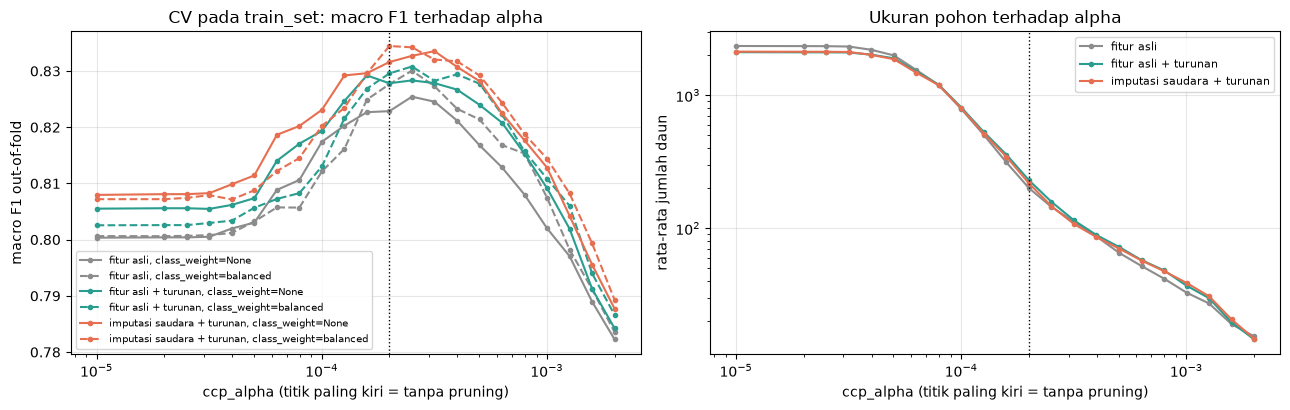

In [26]:
# Kurva CV: macro F1 terbaik per alpha (threshold disetel) dan rata-rata jumlah daun.
fig, (ax_f1, ax_leaves) = plt.subplots(1, 2, figsize=(13, 4.2))
colors = dict(zip(DTL_VARIANTS, ['#8c8c8c', '#2a9d8f', '#e76f51']))
plot_alphas = np.where(DTL_ALPHAS == 0, DTL_ALPHAS[1] / 2, DTL_ALPHAS)
for (variant, class_weight), group in dtl_search.groupby(['variant', 'class_weight'], sort=False):
    curve = group.groupby('alpha')['oof_macro_f1'].max().reindex(DTL_ALPHAS)
    style = '-' if class_weight == 'None' else '--'
    ax_f1.plot(plot_alphas, curve, style, color=colors[variant], marker='o', markersize=3,
               label=f'{variant}, class_weight={class_weight}')
    if class_weight == 'None':
        leaves = group.groupby('alpha')['leaves'].first().reindex(DTL_ALPHAS)
        ax_leaves.plot(plot_alphas, leaves, color=colors[variant], marker='o', markersize=3, label=variant)
for ax in (ax_f1, ax_leaves):
    ax.set_xscale('log')
    ax.axvline(DTL_PARAMS['ccp_alpha'], color='black', linestyle=':', linewidth=1)
    ax.set_xlabel('ccp_alpha (titik paling kiri = tanpa pruning)')
    ax.grid(alpha=.3)
ax_f1.set_ylabel('macro F1 out-of-fold')
ax_f1.set_title('CV pada train_set: macro F1 terhadap alpha')
ax_f1.legend(fontsize=7.5, loc='lower left')
ax_leaves.set_yscale('log')
ax_leaves.set_ylabel('rata-rata jumlah daun')
ax_leaves.set_title('Ukuran pohon terhadap alpha')
ax_leaves.legend(fontsize=8)
fig.tight_layout()
fig.savefig(CFG.OUTPUT_DIR / 'dtl_ccp_cv.png', dpi=150, bbox_inches='tight')
plt.show()

**Analisis CV.** Tanpa pruning, pohon tumbuh sampai sekitar 2.100–2.400 daun dengan macro F1 out-of-fold hanya 0,800–0,808. Kurva macro F1 terhadap $\alpha$ berbentuk ∩, sesuai trade-off bias–variance. Pada $\alpha$ kecil pohon *overfit* karena daunnya menghafal kasus individual. Pada $\alpha > 10^{-3}$ pohon terlalu sederhana (kurang dari 40 daun) sehingga skornya turun tajam. Puncaknya ada di $\alpha \approx 1{,}6$–$4 \cdot 10^{-4}$, yaitu 100–350 daun. Pada titik ini pruning saja menaikkan macro F1 OOF sekitar 0,025 untuk ketiga varian fitur, sambil memangkas lebih dari 90% daun.

Fitur turunan dan imputasi saudara menggeser seluruh kurva ke atas. Dengan $\alpha$ terbaik dan threshold 0,5, macro F1 OOF naik dari 0,8245 (fitur asli) menjadi 0,8291 (+ fitur turunan) dan 0,8334 (+ imputasi saudara). `class_weight='balanced'` dengan threshold 0,5 justru lebih buruk (0,8231), karena bobot kelas batal yang lebih besar membuat pohon terlalu sering memprediksi batal. Setelah threshold digeser ke 0,72, skornya menjadi yang tertinggi (0,8344). Peluang berbobot 0,72 setara dengan peluang batal asli sekitar 0,55, sehingga keputusan akhirnya tetap dekat aturan mayoritas. Selisihnya terhadap varian tanpa bobot (0,8335) hanya 0,0009, jadi keduanya praktis setara. Kami tetap memakai konfigurasi dengan skor OOF tertinggi agar pemilihan sepenuhnya mengikuti prosedur CV.

Ablasi DTL pada val_set:
                                langkah  macro_f1  accuracy  f1_tidak_batal  f1_batal  daun  kedalaman  fit_detik
1. Awal: 5.000 baris, depth 10, leaf 20    0.7684    0.8078          0.8639    0.6729   139         10     2.0982
2. Seluruh train_set, depth 10, leaf 20    0.8181    0.8436          0.8862    0.7500   247         10     3.1872
           3. Pohon penuh tanpa pruning    0.8022    0.8248          0.8690    0.7354  2915         39    12.5290
           4. + cost-complexity pruning    0.8303    0.8537          0.8933    0.7672   122         13    14.6853
  5. + fitur turunan & imputasi saudara    0.8290    0.8544          0.8949    0.7632   101         13    16.5571
  6. + class weight & threshold (final)    0.8386    0.8593          0.8964    0.7808   201         15    22.0077


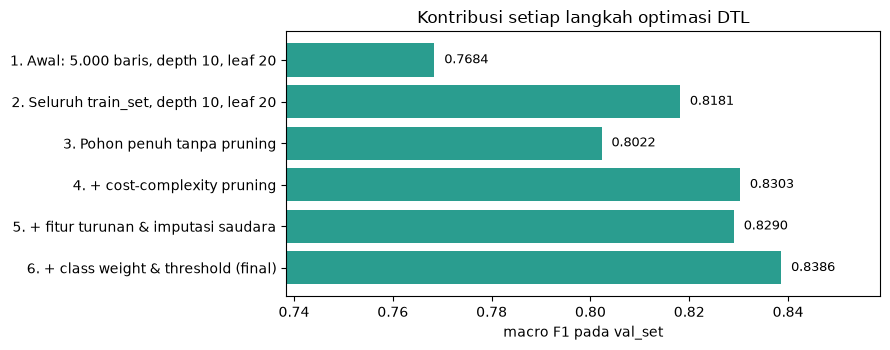

In [27]:
# Ablasi pada val_set: setiap langkah menambah satu perubahan. Konfigurasi sudah dikunci oleh CV.
def tree_matrix_for_sklearn(fit_frame, frame):
    # One-hot kategori untuk scikit-learn; nilai kosong tetap NaN karena DecisionTreeClassifier
    # mendukung missing value secara bawaan.
    parts = [frame.drop(columns=CATEGORICAL_COLUMNS).astype(float)]
    for column in CATEGORICAL_COLUMNS:
        levels = sorted(fit_frame[column].dropna().unique())
        onehot = pd.DataFrame({f'{column}={level}': (frame[column] == level).astype(float)
                               for level in levels}, index=frame.index)
        onehot[frame[column].isna()] = np.nan
        parts.append(onehot)
    return pd.concat(parts, axis=1).to_numpy()


def best_alpha(variant, class_weight='None'):
    rows = dtl_search[(dtl_search['variant'] == variant) & (dtl_search['class_weight'] == class_weight)
                      & (dtl_search['threshold'] == .5)]
    return float(best_dtl_row(rows)['alpha'])


raw_prep = make_tree_preprocessor(derived=False, sibling_imputation=False).fit(train_set)
dtl_prep = make_tree_preprocessor(**DTL_PREP_KWARGS).fit(train_set)
X_train_tree, X_val_tree = dtl_prep.transform(train_set), dtl_prep.transform(val_set)
X_train_tree_sk = tree_matrix_for_sklearn(X_train_tree, X_train_tree)
X_val_tree_sk = tree_matrix_for_sklearn(X_train_tree, X_val_tree)

dtl_steps = [
    ('1. Awal: 5.000 baris, depth 10, leaf 20', None, None),
    ('2. Seluruh train_set, depth 10, leaf 20', raw_prep, dict(max_depth=10, min_samples_leaf=20)),
    ('3. Pohon penuh tanpa pruning', raw_prep, dict()),
    ('4. + cost-complexity pruning', raw_prep, dict(ccp_alpha=best_alpha('fitur asli'))),
    ('5. + fitur turunan & imputasi saudara', dtl_prep,
     dict(ccp_alpha=best_alpha(DTL_BEST['variant']))),
    ('6. + class weight & threshold (final)', dtl_prep, DTL_PARAMS),
]
dtl_ablation, dtl_models = [], {}
for name, prep, params in dtl_steps:
    if prep is None:
        model, predicted = models['CART'], predictions['CART']
        fit_seconds = next(row['fit_seconds'] for row in results if row['model'] == 'CART')
    else:
        X_fit, X_eval = prep.transform(train_set), prep.transform(val_set)
        start = perf_counter()
        model = DecisionTree(**params).fit(X_fit, y_train_array)
        fit_seconds = perf_counter() - start
        predicted = model.predict(X_eval)
    dtl_models[name] = (model, predicted)
    f1_per_class = f1_score(y_valid, predicted, average=None)
    dtl_ablation.append({
        'langkah': name, 'macro_f1': f1_score(y_valid, predicted, average='macro'),
        'accuracy': accuracy_score(y_valid, predicted), 'f1_tidak_batal': f1_per_class[0],
        'f1_batal': f1_per_class[1], 'daun': model.n_leaves_, 'kedalaman': model.depth_,
        'fit_detik': fit_seconds,
    })
dtl_ablation = pd.DataFrame(dtl_ablation)
print('Ablasi DTL pada val_set:')
print(dtl_ablation.round(4).to_string(index=False))

# Model final DTL menggantikan baseline pada perbandingan semua model.
dtl_final, dtl_val_pred = dtl_models[dtl_steps[-1][0]]
models['CART'], predictions['CART'] = dtl_final, dtl_val_pred
model_factories['CART'] = ('tree', lambda: DecisionTree(**DTL_PARAMS))
model_inputs['tree'] = (X_train_tree, X_val_tree)
for row in results:
    if row['model'] == 'CART':
        row.update(macro_f1=dtl_ablation['macro_f1'].iloc[-1], accuracy=dtl_ablation['accuracy'].iloc[-1],
                   fit_seconds=dtl_ablation['fit_detik'].iloc[-1])

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(dtl_ablation['langkah'][::-1], dtl_ablation['macro_f1'][::-1], color='#2a9d8f')
for y_position, value in enumerate(dtl_ablation['macro_f1'][::-1]):
    ax.text(value + .002, y_position, f'{value:.4f}', va='center', fontsize=9)
ax.set_xlim(dtl_ablation['macro_f1'].min() - .03, dtl_ablation['macro_f1'].max() + .02)
ax.set_xlabel('macro F1 pada val_set')
ax.set_title('Kontribusi setiap langkah optimasi DTL')
fig.tight_layout()
fig.savefig(CFG.OUTPUT_DIR / 'dtl_ablation.png', dpi=150, bbox_inches='tight')
plt.show()

**Analisis ablasi (val_set).** Macro F1 DTL naik dari **0,7684** menjadi **0,8386** (+0,070). Kontribusi setiap langkah:

- **Data training penuh (+0,050).** Penyebab terbesar skor awal yang rendah adalah sampel 5.000 baris. Dengan parameter yang sama, seluruh `train_set` menaikkan F1 kelas batal dari 0,673 ke 0,750.
- **Pohon penuh tanpa pruning (−0,016 dari langkah 2).** Tanpa batas, pohon tumbuh ke 2.915 daun dan kedalaman 39. Akurasi training-nya sempurna, tetapi macro F1 validasi turun ke 0,8022. Ini bukti *overfitting* yang ditangani pruning.
- **Cost-complexity pruning (+0,028 dari pohon penuh).** Pohon dipangkas menjadi 122 daun dan kedalaman 13. Hasilnya (0,8303) lebih baik daripada `max_depth=10, min_samples_leaf=20` yang dipilih manual (0,8181), karena pruning memangkas berdasarkan manfaat setiap subpohon, bukan memotong rata di kedalaman tertentu.
- **Fitur turunan dan imputasi saudara (−0,001).** Di CV langkah ini memberi +0,009, tetapi di validasi skornya turun tipis. Selisih 0,001 berada dalam variasi acak satu split validasi berisi 5.474 baris, sehingga hasil CV pada lima fold lebih bisa diandalkan. Akurasi dan F1 kelas tidak batal tetap naik sedikit.
- **Class weight dan threshold (+0,010).** Langkah ini paling memperbaiki kelas minoritas: F1 batal naik dari 0,763 ke 0,781, recall batal 0,764, dan precision batal 0,798.

Seluruh konfigurasi dipilih dengan CV pada `train_set`, sehingga skor validasi 0,8386 tidak bias oleh pemilihan hyperparameter.

              precision    recall  f1-score   support

 tidak batal     0.8874    0.9057    0.8964      3680
       batal     0.7980    0.7642    0.7808      1794

    accuracy                         0.8593      5474
   macro avg     0.8427    0.8350    0.8386      5474
weighted avg     0.8581    0.8593    0.8585      5474



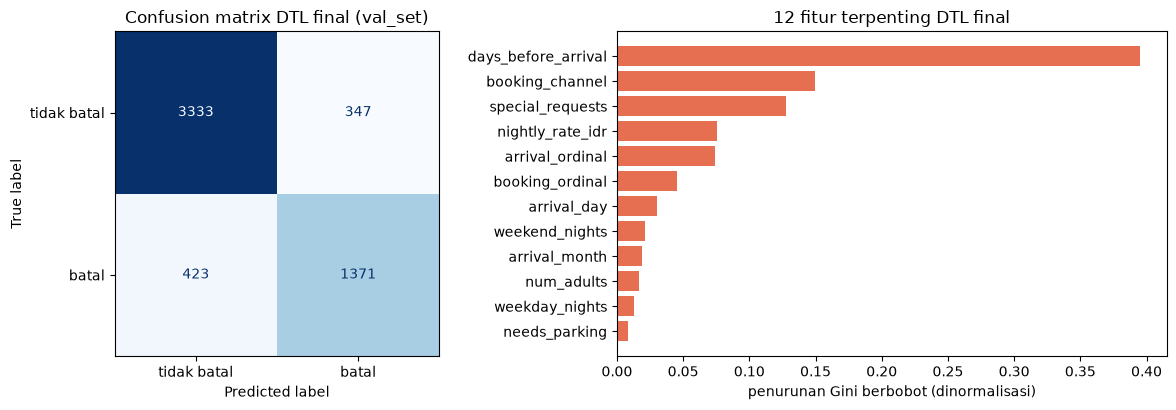

In [28]:
# Evaluasi rinci DTL final pada val_set.
print(classification_report(y_valid, dtl_val_pred, digits=4, target_names=['tidak batal', 'batal']))

fig, (ax_cm, ax_imp) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1, 1.5]})
ConfusionMatrixDisplay.from_predictions(y_valid, dtl_val_pred, display_labels=['tidak batal', 'batal'],
                                        cmap='Blues', colorbar=False, ax=ax_cm)
ax_cm.set_title('Confusion matrix DTL final (val_set)')
importances = pd.Series(dtl_final.feature_importances_, index=dtl_final.feature_names_in_)
importances = importances.sort_values().tail(12)
ax_imp.barh(importances.index, importances.values, color='#e76f51')
ax_imp.set_xlabel('penurunan Gini berbobot (dinormalisasi)')
ax_imp.set_title('12 fitur terpenting DTL final')
fig.tight_layout()
fig.savefig(CFG.OUTPUT_DIR / 'dtl_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

**Analisis evaluasi.** F1 kelas tidak batal (0,896) jauh di atas kelas batal (0,781). Kelas batal hanya sepertiga data dan polanya lebih beragam. Dari 1.794 pemesanan batal, 423 tidak terdeteksi (*false negative*), sedangkan 347 pemesanan yang datang diprediksi batal (*false positive*). Jumlah kedua jenis kesalahan cukup seimbang karena threshold dipilih untuk macro F1, yang memberi bobot sama pada kedua kelas.

`days_before_arrival` menyumbang sekitar 40% penurunan Gini, sejalan dengan eksplorasi data: median lead time di training adalah 117 hari untuk pemesanan batal dan 41 hari untuk yang tidak batal. Berikutnya `booking_channel` (15%), `special_requests` (13%), `nightly_rate_idr`, dan `arrival_ordinal`. Dua fitur turunan, `arrival_ordinal` dan `booking_ordinal`, masuk enam besar. Pohon memanfaatkan posisi tanggal secara absolut untuk menangkap periode dengan tingkat pembatalan tinggi, yang sulit dibentuk dari kombinasi tahun, bulan, dan hari secara terpisah.

### Visualisasi Pohon (Bonus)

`plot_decision_tree(model, top_n=N)` menggambar N percabangan terpenting. Percabangan dipilih secara *best-first* dari akar berdasarkan penurunan Gini berbobot, sehingga yang tampil selalu terhubung ke akar dan paling berpengaruh. Subpohon di luar N split teratas diringkas menjadi kotak putus-putus. Warna kotak menunjukkan proporsi pemesanan batal, tebal panah menunjukkan jumlah data, dan label `NaN` menunjukkan arah nilai kosong.

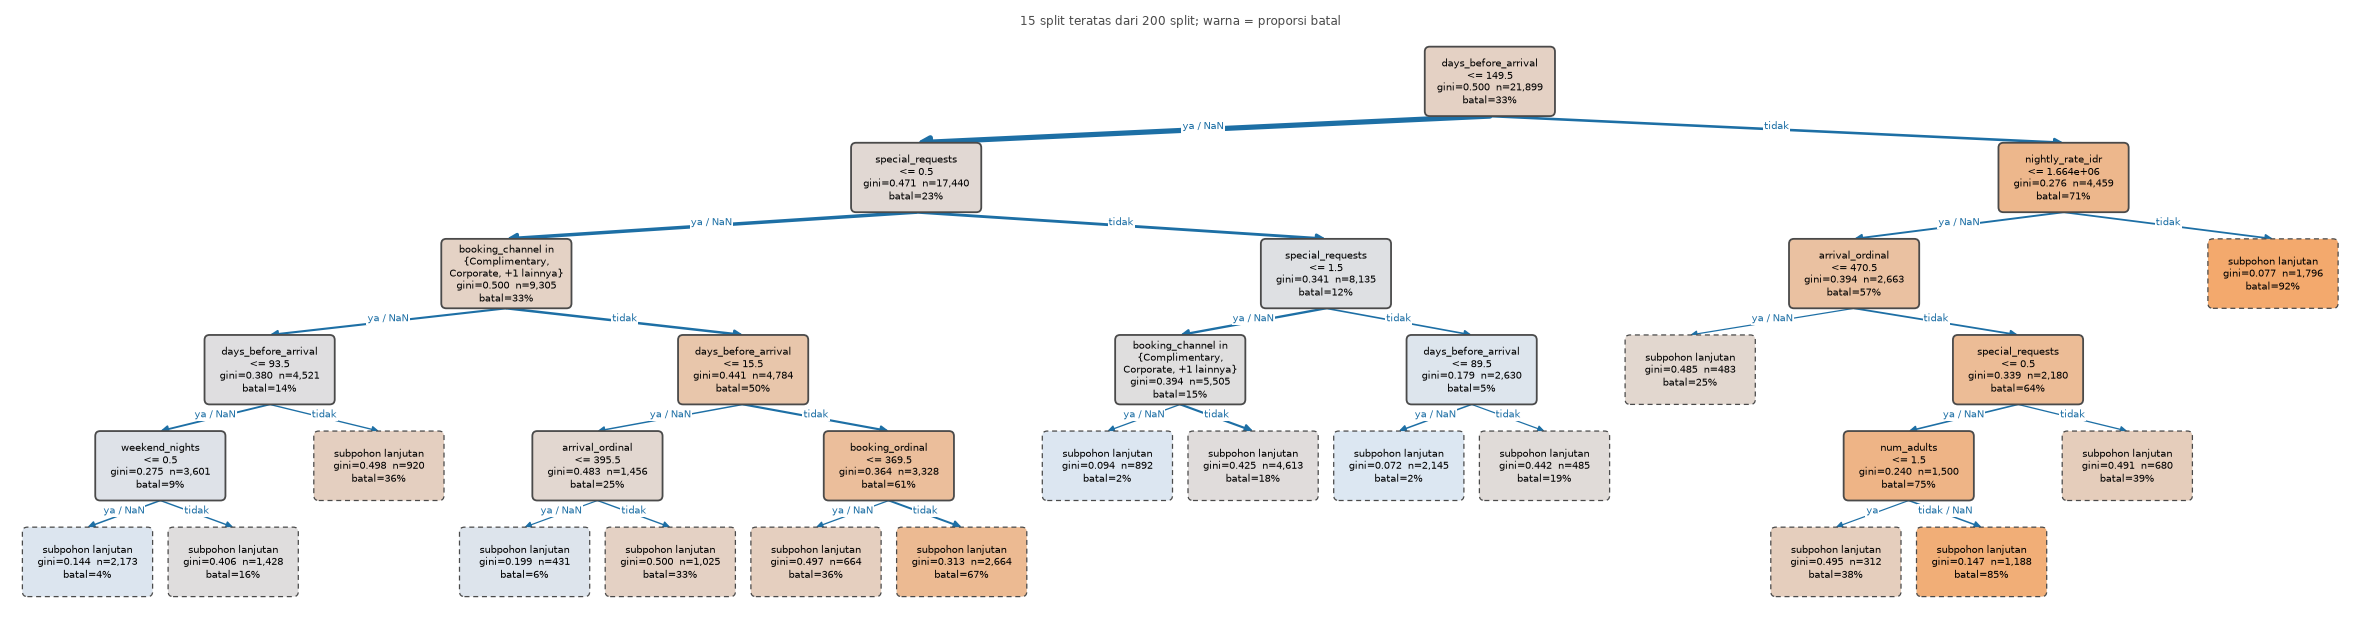

Pohon final: 201 daun, kedalaman 15, dari pohon penuh 2623 daun


In [29]:
DTL_TOP_N = 15
ax = plot_decision_tree(dtl_final, top_n=DTL_TOP_N)
ax.figure.savefig(CFG.OUTPUT_DIR / f'dtl_tree_top{DTL_TOP_N}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Pohon final: {dtl_final.n_leaves_} daun, kedalaman {dtl_final.depth_}, '
      f'dari pohon penuh {dtl_final.full_tree_n_leaves_} daun')

**Membaca pohon.** Split pertama memisahkan pemesanan dengan lead time di atas 149,5 hari. Di cabang ini 71% pemesanan batal, dan jika harga per malam juga tinggi (> Rp1,66 juta) proporsinya naik menjadi 92%. Pemesanan dengan lead time lebih pendek dipecah oleh `special_requests`. Tamu yang mengajukan permintaan khusus jarang membatalkan (12%, dan hanya 5% jika permintaannya lebih dari satu). Tanpa permintaan khusus, pemesanan lewat kanal `Complimentary`, `Corporate`, atau `Offline Agent` jauh lebih jarang batal (14%) dibanding `Online Travel Agent` dan `Airline` (50%). Untuk nilai kosong, `days_before_arrival` dan `special_requests` mengikuti cabang kiri (risiko lebih rendah). Pohon mempelajari arah ini langsung dari data, tanpa imputasi.

Nilai Gini pada gambar dihitung dengan bobot kelas (`class_weight='balanced'`), sehingga Gini akar 0,5. Persentase batal menunjukkan proporsi asli di data training.

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [30]:
for name in ('LogReg L1', 'LogReg L2', 'LogReg Elastic Net'):
    evaluate(name)

LogReg L1 {'macro_f1': 0.745, 'accuracy': 0.7939, 'fit_seconds': 0.3274, 'predict_seconds': 0.0167}


LogReg L2 {'macro_f1': 0.7458, 'accuracy': 0.793, 'fit_seconds': 0.2301, 'predict_seconds': 0.0024}


LogReg Elastic Net {'macro_f1': 0.7445, 'accuracy': 0.7928, 'fit_seconds': 0.205, 'predict_seconds': 0.0035}


Ketiga bentuk regularisasi dilatih pada matriks numerik yang sama. Perbandingan ini menunjukkan pengaruh L1, L2, dan Elastic Net pada data validasi.

### Optimasi Logistic Regression: FISTA

Di kelas, bobot Logistic Regression diperbarui dengan *gradient descent* atau *stochastic gradient ascent* dengan *learning rate* tetap. Implementasi kami memakai **FISTA** (*Fast Iterative Shrinkage-Thresholding Algorithm*) karena dua alasan: regularisasi L1 tidak dapat diturunkan di titik nol, dan *gradient descent* biasa lambat ketika fitur saling berkorelasi.

Fungsi objektifnya adalah rata-rata *log-loss* ditambah penalti, $F(w, b) = f(w, b) + \lambda\rho\lVert w\rVert_1$, dengan $f$ berisi *log-loss* dan bagian L2 yang dapat diturunkan. Setiap iterasi terdiri atas empat langkah:

1. **Langkah gradien** pada bagian yang dapat diturunkan: $v = y_k - t\,\nabla f(y_k)$.
2. **Operator proksimal** untuk L1, yaitu *soft-thresholding*: $w_{k+1} = \operatorname{sign}(v)\max(|v| - t\lambda\rho, 0)$. Bobot yang kecil langsung menjadi nol, sehingga L1 dan Elastic Net menghasilkan model yang jarang (*sparse*).
3. **Momentum Nesterov**: titik berikutnya diekstrapolasi, $y_{k+1} = w_{k+1} + \frac{m_k - 1}{m_{k+1}}(w_{k+1} - w_k)$ dengan $m_{k+1} = \frac{1 + \sqrt{1 + 4m_k^2}}{2}$. Momentum ini menaikkan laju konvergensi dari $O(1/k)$ menjadi $O(1/k^2)$ (Beck & Teboulle, 2009).
4. **Backtracking** memilih ukuran langkah $t$ secara otomatis, sehingga tidak perlu menyetel *learning rate*. Jika nilai objektif naik, momentum di-*restart* agar iterasi tidak berosilasi (O'Donoghue & Candès, 2015).

Sel berikut membandingkan FISTA dengan *proximal gradient* tanpa momentum (`accelerate=False`) pada data dan regularisasi yang sama.

             model        optimizer  iterations  seconds  objective
         LogReg L1            FISTA          58 0.158969   0.476716
         LogReg L1 tanpa akselerasi         330 0.488380   0.476716
         LogReg L2            FISTA          41 0.057341   0.446893
         LogReg L2 tanpa akselerasi         181 0.293222   0.446893
LogReg Elastic Net            FISTA          35 0.050389   0.463485
LogReg Elastic Net tanpa akselerasi         193 0.333690   0.463485


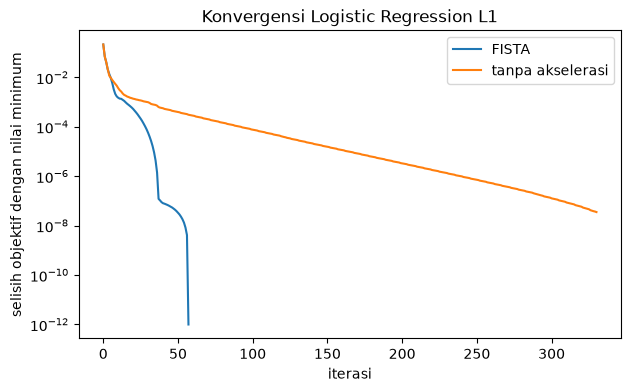

In [31]:
X_fit_numeric, _ = model_inputs['numeric']
fista_rows, loss_curves = [], {}
for name, params in logreg_params.items():
    for label, accelerate in (('FISTA', True), ('tanpa akselerasi', False)):
        start = perf_counter()
        model = LogisticRegression(**{**params, 'max_iter': 10_000}, accelerate=accelerate).fit(X_fit_numeric, y_model)
        fista_rows.append({'model': name, 'optimizer': label, 'iterations': model.n_iter_,
                           'seconds': perf_counter() - start, 'objective': model.loss_history_[-1]})
        if name == 'LogReg L1':
            loss_curves[label] = np.array(model.loss_history_)
print(pd.DataFrame(fista_rows).round(6).to_string(index=False))

best_objective = min(curve.min() for curve in loss_curves.values())
fig, ax = plt.subplots(figsize=(7, 4))
for label, curve in loss_curves.items():
    ax.semilogy(curve - best_objective + 1e-12, label=label)
ax.set_xlabel('iterasi')
ax.set_ylabel('selisih objektif dengan nilai minimum')
ax.set_title('Konvergensi Logistic Regression L1')
ax.legend()
plt.show()

FISTA mencapai nilai objektif yang sama persis dengan *proximal gradient* biasa, tetapi dengan iterasi 4,4–5,7 kali lebih sedikit: 58 vs 330 iterasi untuk L1, 41 vs 181 untuk L2, dan 35 vs 193 untuk Elastic Net. Karena titik akhirnya sama, perbedaan keduanya hanya pada kecepatan mencapai minimum, bukan pada kualitas model. Grafik konvergensi L1 menunjukkan selisih objektif FISTA turun jauh lebih curam sejak iterasi awal.

### Video Kontur Log-Loss (Bonus)

Video berikut menampilkan garis kontur *log-loss* dan lintasan parameter $(\theta_0, \theta_1)$ selama training. Agar ruang parameternya dua dimensi, model dilatih dengan satu fitur, yaitu `days_before_arrival` dalam satuan ratusan hari, sehingga $\theta_0$ adalah intercept dan $\theta_1$ adalah bobot fitur tersebut. Kedua lintasan dimulai dari $(0, 0)$: oranye untuk FISTA dan hijau untuk *proximal gradient* tanpa momentum.

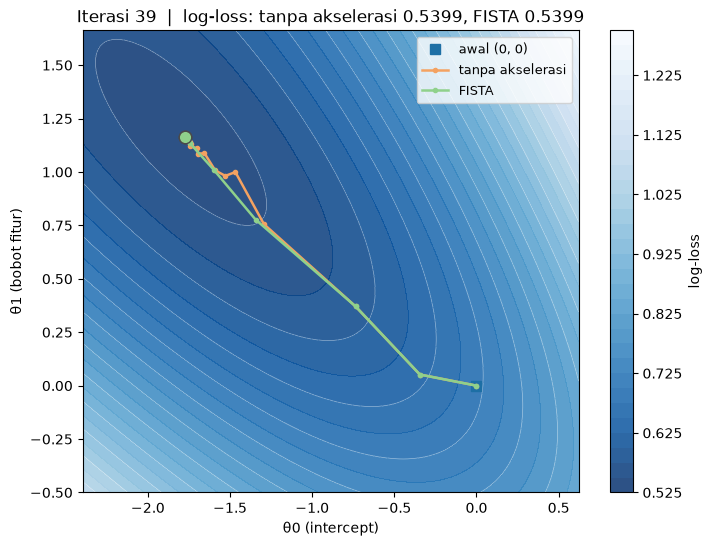

tanpa akselerasi: 39 iterasi, theta0 = -1.775, theta1 = 1.162
FISTA: 20 iterasi, theta0 = -1.775, theta1 = 1.162


In [32]:
lead_hundreds = X_train['days_before_arrival'].to_numpy(dtype=float) / 100
single_feature = lead_hundreds.reshape(-1, 1)
path_models = {
    label: LogisticRegression(penalty='l2', reg_strength=1e-3, max_iter=3000, tol=1e-6,
                              accelerate=accelerate, record_path=True).fit(single_feature, y_train)
    for label, accelerate in (('tanpa akselerasi', False), ('FISTA', True))
}
video_path = CFG.OUTPUT_DIR / 'logreg_loss_path.mp4'
last_frame = save_loss_path_video(path_models, lead_hundreds, y_train.to_numpy(), video_path)
plt.show()
for label, model in path_models.items():
    print(f'{label}: {len(model.path_) - 1} iterasi, theta0 = {model.intercept_:.3f}, theta1 = {model.coef_[0]:.3f}')
display(Video(str(video_path), embed=True, html_attributes='controls loop'))

Kontur *log-loss* berbentuk elips miring karena intercept dan bobot `days_before_arrival` saling berkorelasi: kenaikan $\theta_1$ harus diimbangi dengan penurunan $\theta_0$. Kedua lintasan berakhir di minimum yang sama ($\theta_0 \approx -1{,}78$, $\theta_1 \approx 1{,}16$). FISTA sampai dalam 20 iterasi, sedangkan tanpa akselerasi butuh 39 iterasi karena langkahnya mengecil ketika menyusuri lembah elips yang sempit. Nilai $\theta_1$ yang positif berarti peluang batal naik seiring jauhnya jarak antara pemesanan dan kedatangan.

<!-- rubric v3: total slack, slack_total -->

## Support Vector Machine

This part covers the linear, polynomial, and Gaussian kernels.

In [33]:
for name in ('SVM Linear', 'SVM Polynomial', 'SVM Gaussian'):
    evaluate(name)

SVM Linear {'macro_f1': 0.7588, 'accuracy': 0.7994, 'fit_seconds': 30.3528, 'predict_seconds': 0.0833}


SVM Polynomial {'macro_f1': 0.7916, 'accuracy': 0.8202, 'fit_seconds': 29.2522, 'predict_seconds': 0.5164}


SVM Gaussian {'macro_f1': 0.8114, 'accuracy': 0.8356, 'fit_seconds': 6.8714, 'predict_seconds': 0.7535}


Kernel linear, polinomial, dan Gaussian diuji pada sampel training yang sama. Hasil validasi menunjukkan apakah batas keputusan nonlinier membantu klasifikasi pemesanan.

### Optimasi SVM: SMO dengan Working Set Selection Orde Dua

Di kelas, SVM dilatih dengan menyelesaikan bentuk dual Lagrangian sebagai *quadratic programming* (QP). QP umum membutuhkan matriks kernel $n \times n$ secara utuh, yaitu sekitar 3,8 GB untuk 21.899 baris training, sehingga tidak praktis untuk data ini. Implementasi kami memakai **Sequential Minimal Optimization** (SMO, Platt, 1998):

1. Setiap iterasi hanya mengubah dua koefisien dual $\alpha_i$ dan $\alpha_j$. Karena batasan $\sum_k y_k\alpha_k = 0$ harus tetap terpenuhi, subproblem dua variabel ini punya solusi analitik, sehingga tidak perlu solver QP.
2. Gradien dual diperbarui dengan dua baris kernel saja. Baris kernel yang sering dipakai disimpan dalam *cache* LRU, jadi matriks kernel penuh tidak pernah dibentuk.
3. Training berhenti ketika pelanggaran kondisi KKT terbesar di bawah toleransi (`tol`).

Kunci kecepatan SMO ada pada pemilihan pasangan $(i, j)$. Indeks $i$ adalah pelanggar KKT terbesar. Untuk $j$, SMO klasik memilih pelanggar terbesar di sisi lain (*maximal violating pair*, Keerthi dkk., 2001). Kami memakai **pemilihan orde dua** (Fan, Chen, & Lin, 2005), yang memilih $j$ dengan penurunan objektif dual terbesar:

$$j = \arg\min_t \; -\frac{b_{it}^2}{a_{it}}, \qquad a_{it} = K_{ii} + K_{tt} - 2K_{it},\quad b_{it} = -y_i\nabla_i + y_t\nabla_t.$$

Rumus ini memakai kelengkungan objektif ($a_{it}$), bukan hanya gradien, sehingga setiap langkah lebih efektif dan jumlah iterasi berkurang. Sel berikut membandingkan kedua cara pemilihan pada SVM Gaussian.

In [34]:
X_fit_svm, X_eval_svm = model_inputs['svm']
smo_rows, smo_predictions = [], {}
for selection in ('second_order', 'first_order'):
    start = perf_counter()
    model = SVM(kernel='gaussian', selection=selection, **svm_params['gaussian']).fit(X_fit_svm, y_model)
    smo_predictions[selection] = model.predict(X_eval_svm)
    smo_rows.append({'selection': selection, 'iterations': model.n_iter_, 'seconds': perf_counter() - start,
                     'support_vectors': len(model.support_),
                     'macro_f1': f1_score(y_valid, smo_predictions[selection], average='macro')})
print(pd.DataFrame(smo_rows).round(4).to_string(index=False))
print('Kesamaan prediksi kedua cara:', np.mean(smo_predictions['second_order'] == smo_predictions['first_order']))

   selection  iterations  seconds  support_vectors  macro_f1
second_order        9454  10.4055             2530    0.8114
 first_order       18054  12.3679             2531    0.8114
Kesamaan prediksi kedua cara: 1.0


Kedua cara pemilihan menghasilkan model yang sama: jumlah *support vector* hampir identik (2.530 dan 2.531), macro F1 sama (0,8114), dan prediksi validasi 100% sama. Pemilihan orde dua hanya butuh 9.454 iterasi, hampir setengah dari 18.054 iterasi pada pemilihan orde satu. Waktu training turun dari 12,4 menjadi 10,4 detik. Selisih waktunya lebih kecil daripada selisih iterasi karena setiap iterasi orde dua menghitung kelengkungan untuk semua kandidat $j$.

### Visualisasi Kernel SVM (Bonus)

Data SVM memiliki banyak dimensi, sehingga diproyeksikan ke dua komponen utama (PCA) terlebih dahulu. Dari proyeksi tersebut diambil 400 pemesanan dari setiap kelas agar bidang pemisah tidak tertarik ke kelas mayoritas. Satu SVM dilatih untuk setiap kernel dengan hyperparameter yang sama seperti di atas. Garis tegas adalah bidang pemisah $f(x) = 0$, garis putus-putus adalah margin $f(x) = \pm 1$, dan titik yang dilingkari adalah *support vector*.

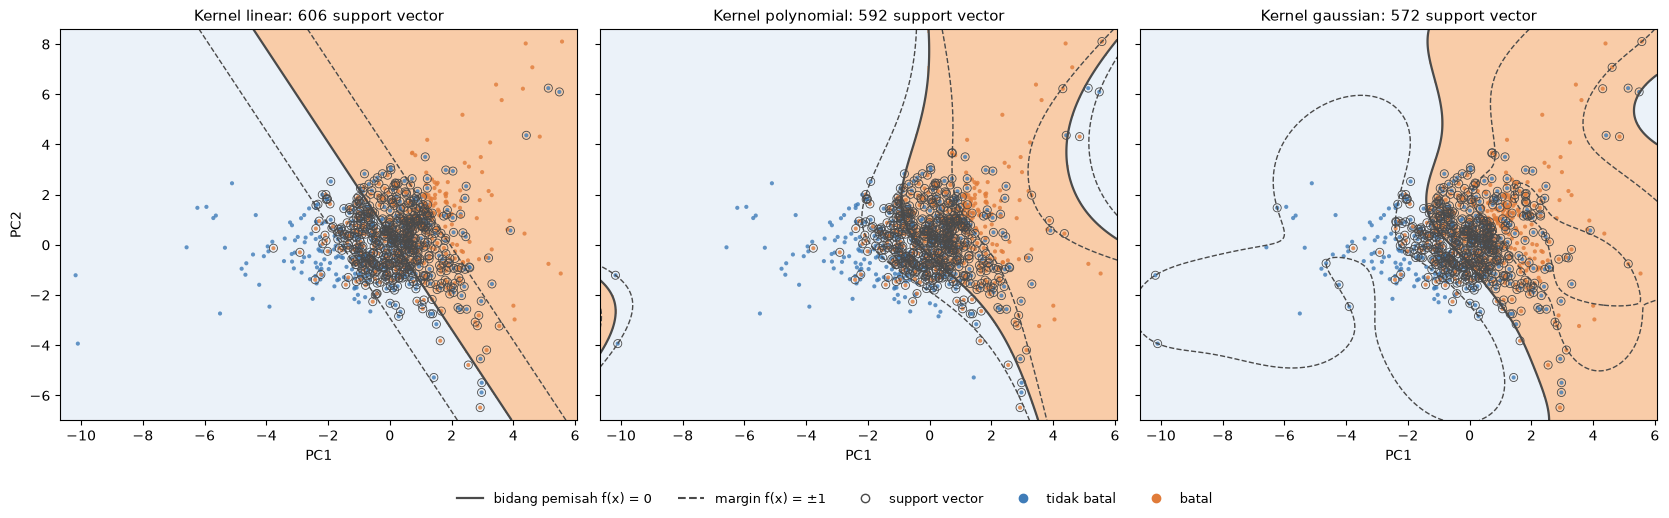

In [35]:
X_train_svm = svm_prep.transform(train_set)
fig = plot_svm_kernels(X_train_svm, y_train.to_numpy(), svm_params, seed=CFG.SEED)
fig.savefig(CFG.OUTPUT_DIR / 'svm_kernels.png', dpi=150, bbox_inches='tight')
plt.show()

Kernel linear menghasilkan bidang pemisah berupa garis lurus, sedangkan kernel polynomial dan Gaussian membentuk batas melengkung yang mengikuti sebaran data. Pada ketiga kernel, sebagian besar *support vector* berada di daerah tengah tempat kedua kelas bertumpuk. Artinya, dua komponen utama belum cukup untuk memisahkan pemesanan batal dan tidak batal, dan pemisahan pada model di atas juga memanfaatkan dimensi lain yang tidak terlihat di proyeksi ini. Kernel Gaussian memiliki *support vector* paling sedikit (572) dan batas paling fleksibel, sejalan dengan macro F1 validasinya yang tertinggi di antara ketiga kernel.

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [36]:
for name in ('Naive Bayes', 'Naive Bayes TAN'):
    evaluate(name)

Naive Bayes {'macro_f1': 0.7371, 'accuracy': 0.7742, 'fit_seconds': 0.0126, 'predict_seconds': 0.0115}
Naive Bayes TAN {'macro_f1': 0.7453, 'accuracy': 0.7868, 'fit_seconds': 0.0323, 'predict_seconds': 0.0052}


Naive Bayes menerima kode kategori nonnegatif dari pipeline diskret. Fitur numerik tertentu dibagi ke dalam bin sebelum peluang kelas dihitung. Versi TAN memakai masukan dan smoothing yang sama, tetapi setiap fitur boleh bergantung pada satu fitur lain selain kelas. Dengan lima ribu baris training yang sama, macro F1 validasi naik dari 0,737 menjadi 0,745.

### Optimasi Naive Bayes: Tree-Augmented Naive Bayes

Naive Bayes mengasumsikan semua fitur saling independen jika kelasnya sudah diketahui. Pada data ini asumsi tersebut jelas tidak terpenuhi. `weekday_nights` dan `weekend_nights` sama-sama menggambarkan lama menginap, sedangkan `nightly_rate_idr` bergantung pada `room_category` dan bulan kedatangan. Akibatnya, informasi yang sama terhitung lebih dari sekali dan peluang kelas menjadi terlalu yakin ke salah satu arah.

Tree-Augmented Naive Bayes (TAN) melonggarkan asumsi tersebut. Selain kelas, setiap fitur boleh memiliki satu fitur induk $\pi(i)$, sehingga peluang yang dipakai menjadi $P(x_i \mid x_{\pi(i)}, c)$. Struktur induk dipelajari dari data training dengan langkah berikut:

1. Hitung *conditional mutual information* $I(X_i; X_j \mid C)$ untuk setiap pasangan fitur. Nilai ini mengukur seberapa banyak informasi yang dibagi dua fitur setelah kelasnya diketahui.
2. Bentuk graf lengkap antarfitur dengan bobot $I(X_i; X_j \mid C)$, lalu cari *maximum spanning tree* dengan algoritma Prim.
3. Jadikan fitur dengan *mutual information* terbesar terhadap kelas sebagai akar, lalu arahkan semua sisi menjauhi akar.
4. Hitung tabel peluang $P(x_i \mid x_{\pi(i)}, c)$ dengan Laplace smoothing yang sama seperti Naive Bayes.

Langkah tersebut mengoptimasi struktur model. Friedman dkk. (1997) membuktikan, dengan memperluas hasil Chow dan Liu (1968), bahwa pohon dari langkah 2 memaksimalkan *log-likelihood* data training di antara semua struktur yang setiap fiturnya hanya memiliki kelas dan paling banyak satu fitur lain sebagai induk. Struktur optimal itu didapat tanpa pencarian iteratif, cukup dengan satu kali perhitungan statistik dan satu kali pencarian pohon. Naive Bayes biasa adalah kasus khusus TAN tanpa sisi antarfitur, sehingga keduanya memakai kelas dasar yang sama dan hanya berbeda pada cara mempelajari induk fitur.

In [37]:
# Pipeline diskret di-fit ulang pada setiap fold agar statistik bin hanya berasal dari fold training.
nb_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)
y_labels = train_df['is_canceled'].to_numpy()
nb_variants = {'Naive Bayes': NaiveBayes, 'Naive Bayes TAN': TreeAugmentedNaiveBayes}
nb_cv_f1 = {name: [] for name in nb_variants}
nb_cv_log_likelihood = {name: [] for name in nb_variants}
for fit_rows, eval_rows in nb_cv.split(train_df, y_labels):
    fold_prep = make_discrete_preprocessor(n_bins=5).fit(train_df.iloc[fit_rows])
    X_fold_fit = fold_prep.transform(train_df.iloc[fit_rows])
    X_fold_eval = fold_prep.transform(train_df.iloc[eval_rows])
    y_fold_eval = y_labels[eval_rows]
    for name, model_class in nb_variants.items():
        fold_model = model_class(alpha=1).fit(X_fold_fit, y_labels[fit_rows])
        nb_cv_f1[name].append(f1_score(y_fold_eval, fold_model.predict(X_fold_eval), average='macro'))
        log_proba = fold_model.predict_log_proba(X_fold_eval)
        nb_cv_log_likelihood[name].append(log_proba[np.arange(len(eval_rows)), y_fold_eval].mean())

nb_cv_df = pd.DataFrame(nb_cv_f1, index=[f'fold {fold}' for fold in range(1, 6)])
nb_cv_df.loc['mean'] = nb_cv_df.mean()
nb_cv_df.loc['std'] = nb_cv_df.iloc[:5].std(ddof=0)
print('Macro F1 5-fold CV:')
print(nb_cv_df.round(4).to_string())
print('Rata-rata log-likelihood per baris validasi:',
      {name: round(float(np.mean(values)), 4) for name, values in nb_cv_log_likelihood.items()})

Macro F1 5-fold CV:
        Naive Bayes  Naive Bayes TAN
fold 1       0.7504           0.7735
fold 2       0.7541           0.7763
fold 3       0.7489           0.7747
fold 4       0.7409           0.7582
fold 5       0.7441           0.7612
mean         0.7477           0.7688
std          0.0047           0.0075
Rata-rata log-likelihood per baris validasi: {'Naive Bayes': -0.4628, 'Naive Bayes TAN': -0.4253}


TAN lebih baik daripada Naive Bayes biasa pada kelima fold. Rata-rata macro F1 naik dari 0,748 menjadi 0,769, sekitar tiga kali simpangan baku antarfold. Rata-rata log-likelihood per baris validasi juga naik dari −0,463 menjadi −0,425, artinya TAN memberi peluang yang lebih tinggi pada kelas yang benar. Kenaikan ini sesuai dengan tujuan optimasinya, karena struktur TAN dipilih untuk memaksimalkan likelihood. Kenaikan tersebut juga terlihat pada fold validasi yang tidak dipakai saat training, sehingga tambahan sisi antarfitur tidak membuat model *overfit*.

Meski begitu, TAN masih berada di bawah KNN dan SVM. Kedua varian Naive Bayes hanya membaca `days_before_arrival` dan `nightly_rate_idr` dalam lima bin, sehingga detail yang paling berguna bagi KNN, yaitu kemiripan tanggal dan harga antarpemesanan saudara, ikut hilang.

### Graf Bayesian Network

Graf berikut menggambarkan struktur TAN yang dipelajari dari seluruh bagian training. Kelas `is_canceled` menjadi induk semua fitur, seperti pada Naive Bayes. Hubungan ini digambarkan dengan satu panah putus-putus menuju bingkai yang memuat seluruh fitur, sehingga 17 panah kelas tidak menumpuk dengan panah antarfitur. Panah biru di dalam bingkai adalah sisi tambahan dari TAN, dari fitur induk ke fitur anak. Ketebalan dan angka pada panah menunjukkan nilai $I(X_i; X_j \mid C)$ dalam satuan nats.

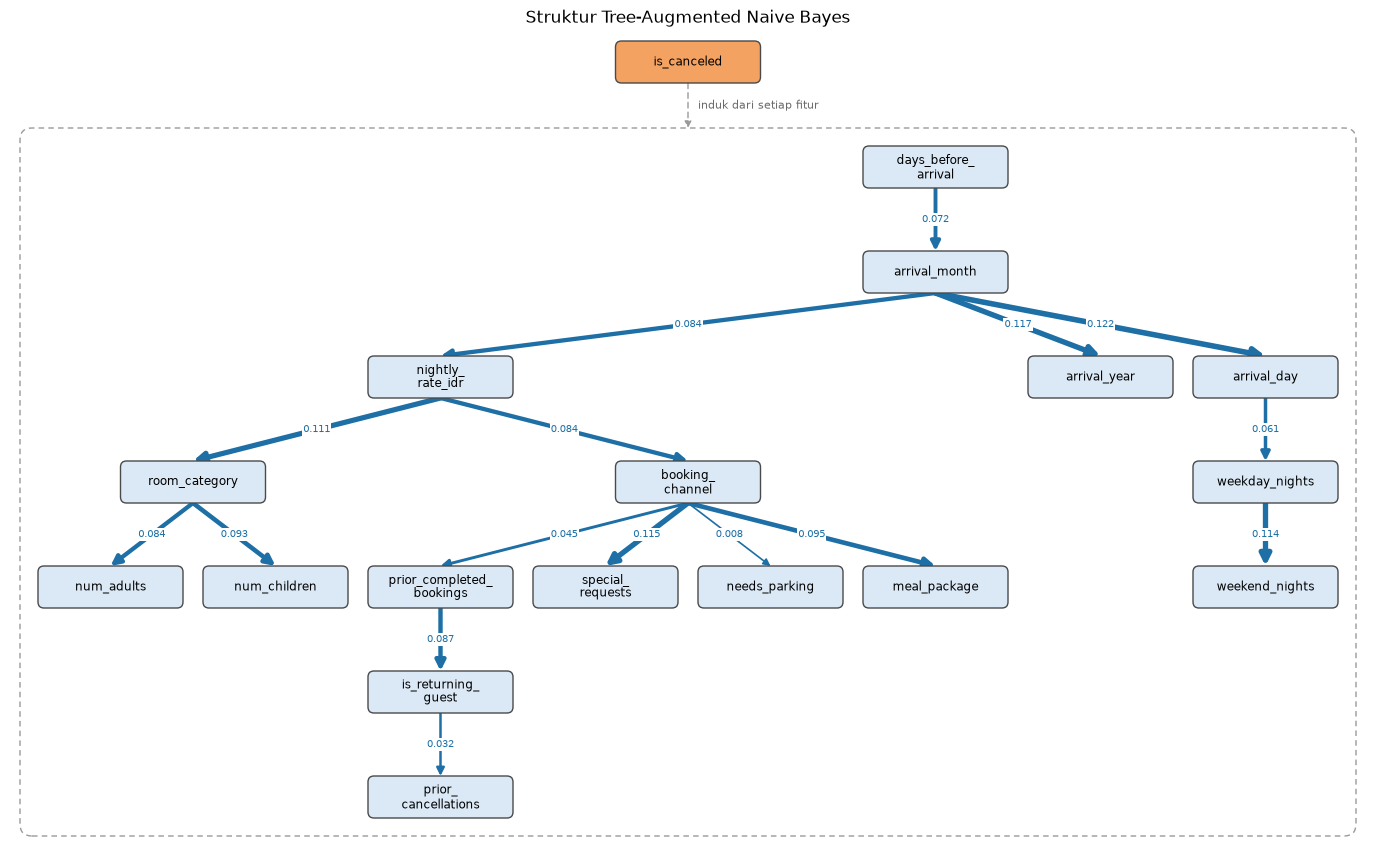

Akar pohon: days_before_arrival
                  parent                    child    cmi
           arrival_month              arrival_day 0.1216
           arrival_month             arrival_year 0.1168
         booking_channel         special_requests 0.1150
          weekday_nights           weekend_nights 0.1144
        nightly_rate_idr            room_category 0.1108
         booking_channel             meal_package 0.0948
           room_category             num_children 0.0927
prior_completed_bookings       is_returning_guest 0.0874
        nightly_rate_idr          booking_channel 0.0843
           arrival_month         nightly_rate_idr 0.0843
           room_category               num_adults 0.0840
     days_before_arrival            arrival_month 0.0721
             arrival_day           weekday_nights 0.0612
         booking_channel prior_completed_bookings 0.0446
      is_returning_guest      prior_cancellations 0.0322
         booking_channel            needs_parking 0.0084

In [38]:
tan_full = TreeAugmentedNaiveBayes(alpha=1).fit(X_train_nb, y_train.to_numpy())
ax = plot_bayesian_network(tan_full, DISCRETE_COLUMNS)
ax.set_title('Struktur Tree-Augmented Naive Bayes')
ax.figure.savefig(CFG.OUTPUT_DIR / 'naive_bayes_tan_graph.png', dpi=150, bbox_inches='tight')
plt.show()

tan_edges = pd.DataFrame(
    [(DISCRETE_COLUMNS[parent], DISCRETE_COLUMNS[child], weight) for parent, child, weight in tan_full.edges_],
    columns=['parent', 'child', 'cmi'],
).sort_values('cmi', ascending=False)
print('Akar pohon:', DISCRETE_COLUMNS[tan_full.root_])
print(tan_edges.round(4).to_string(index=False))

Akar pohon adalah `days_before_arrival`, fitur dengan *mutual information* terbesar terhadap kelas. Hasil ini sejalan dengan eksplorasi data, yang menunjukkan bahwa peluang batal naik tajam seiring bertambahnya jarak antara pemesanan dan kedatangan. Arah panah mengikuti akar pohon, bukan hubungan sebab-akibat. Sisi yang terbentuk juga masuk akal secara domain:

- `arrival_month` menjadi induk `arrival_day`, `arrival_year`, dan `nightly_rate_idr`. Komponen tanggal kedatangan saling terkait, dan harga mengikuti musim.
- `weekday_nights` → `weekend_nights` menghubungkan dua bagian dari lama menginap yang sama.
- `nightly_rate_idr` → `room_category` → `num_adults` dan `num_children` menghubungkan harga, tipe kamar, dan jumlah tamu.
- `booking_channel` menjadi induk `special_requests`, `meal_package`, dan `prior_completed_bookings` karena kebiasaan tamu berbeda pada setiap kanal pemesanan.
- `prior_completed_bookings` → `is_returning_guest` → `prior_cancellations` mengelompokkan riwayat tamu.

Sisi terlemah adalah `booking_channel` → `needs_parking` dengan CMI 0,008. Pohon pada TAN harus menghubungkan semua fitur, sehingga fitur yang hampir independen tetap mendapat satu induk. Pengaruhnya pada prediksi kecil karena peluang `needs_parking` hampir sama untuk setiap kanal setelah kelasnya diketahui.

<!-- figure palette: #6d2fa3 -->

## Model Evaluation

This part compares the validation results of all models.

In [39]:
results_df = pd.DataFrame(results).sort_values(
    ['macro_f1', 'accuracy'], ascending=False
).reset_index(drop=True)
print(results_df.round(4).to_string(index=False))
best_name = results_df.loc[0, 'model']
print('Model dengan macro F1 validasi tertinggi:', best_name)

             model  macro_f1  accuracy  fit_seconds  predict_seconds
              CART    0.8386    0.8593      22.0077           0.4279
               KNN    0.8324    0.8566       0.0028          18.4689
      SVM Gaussian    0.8114    0.8356       6.8714           0.7535
    SVM Polynomial    0.7916    0.8202      29.2522           0.5164
        SVM Linear    0.7588    0.7994      30.3528           0.0833
         LogReg L2    0.7458    0.7930       0.2301           0.0024
   Naive Bayes TAN    0.7453    0.7868       0.0323           0.0052
         LogReg L1    0.7450    0.7939       0.3274           0.0167
LogReg Elastic Net    0.7445    0.7928       0.2050           0.0035
       Naive Bayes    0.7371    0.7742       0.0126           0.0115
Model dengan macro F1 validasi tertinggi: CART


Macro F1 menjadi dasar pemilihan model karena kedua kelas diberi bobot penilaian yang sama. Model diurutkan berdasarkan macro F1 pada data validasi. Jika nilainya sama, akurasi menjadi pembanding kedua sebelum pelatihan akhir.

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [40]:
# 5-fold CV pada seluruh data training untuk memilih threshold KNN.
y_all = train_df['is_canceled'].to_numpy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)
oof_knn = np.zeros(len(train_df))
for fit_rows, eval_rows in cv.split(train_df, y_all):
    fold_prep = make_knn_preprocessor().fit(train_df.iloc[fit_rows])
    fold_model = KNN(**knn_params).fit(fold_prep.transform(train_df.iloc[fit_rows]), y_all[fit_rows])
    oof_knn[eval_rows] = fold_model.predict_proba(fold_prep.transform(train_df.iloc[eval_rows]))[:, 1]

thresholds = np.round(np.arange(.40, .561, .01), 2)
threshold_scores = pd.Series(
    [f1_score(y_all, (oof_knn >= t).astype(int), average='macro') for t in thresholds], index=thresholds)
BEST_THRESHOLD = float(threshold_scores.idxmax())
print('Macro F1 out-of-fold per threshold:')
print(threshold_scores.round(4).to_string())
print('Threshold terpilih:', BEST_THRESHOLD)

# KNN akhir dilatih pada seluruh bagian training lalu diuji pada validasi.
knn_final = KNN(**knn_params, threshold=BEST_THRESHOLD).fit(X_train_knn, y_train.to_numpy())
knn_predicted = knn_final.predict(X_val_knn)
model_factories['KNN'] = ('knn', lambda: KNN(**knn_params, threshold=BEST_THRESHOLD))
models['KNN'], predictions['KNN'] = knn_final, knn_predicted
model_inputs['knn'] = (X_train_knn, X_val_knn)
results_df.loc[results_df['model'] == 'KNN', 'macro_f1'] = f1_score(y_valid, knn_predicted, average='macro')
results_df.loc[results_df['model'] == 'KNN', 'accuracy'] = accuracy_score(y_valid, knn_predicted)
results_df = results_df.sort_values(['macro_f1', 'accuracy'], ascending=False).reset_index(drop=True)
best_name = results_df.loc[0, 'model']
print(results_df[['model', 'macro_f1', 'accuracy']].round(4).to_string(index=False))
print('Model akhir:', best_name)

Macro F1 out-of-fold per threshold:
0.40    0.8562
0.41    0.8569
0.42    0.8584
0.43    0.8596
0.44    0.8603
0.45    0.8605
0.46    0.8613
0.47    0.8611
0.48    0.8612
0.49    0.8610
0.50    0.8606
0.51    0.8601
0.52    0.8589
0.53    0.8582
0.54    0.8564
0.55    0.8555
0.56    0.8543
Threshold terpilih: 0.46


             model  macro_f1  accuracy
               KNN    0.8623    0.8796
              CART    0.8386    0.8593
      SVM Gaussian    0.8114    0.8356
    SVM Polynomial    0.7916    0.8202
        SVM Linear    0.7588    0.7994
         LogReg L2    0.7458    0.7930
   Naive Bayes TAN    0.7453    0.7868
         LogReg L1    0.7450    0.7939
LogReg Elastic Net    0.7445    0.7928
       Naive Bayes    0.7371    0.7742
Model akhir: KNN


Threshold dipilih dari prediksi out-of-fold 5-fold CV pada seluruh data training, bukan dari satu split validasi saja, agar tidak *overfit* pada satu pembagian data. Macro F1 cukup stabil pada threshold 0,46–0,50, dan nilai terbaik ada di 0,46. Threshold sedikit di bawah 0,5 karena kelas batal adalah kelas minoritas.

Setelah dilatih pada seluruh bagian training, KNN mencapai macro F1 validasi 0,862, naik dari 0,832 pada perbandingan 5.000 baris dan di atas DTL yang sudah dioptimasi (0,839) dan SVM Gaussian (0,811). Peningkatan KNN berasal dari tiga hal: penalti untuk atribut diskret yang berbeda, imputasi `days_before_arrival` dari pemesanan saudara, dan bobot fitur hasil *coordinate descent*.

Bobot fitur KNN dicari dengan *coordinate descent*. Setiap fitur dicoba satu per satu dengan bobot 0, 0,6 kali, dan 1,6 kali bobot saat ini (atau 0,3 dan 1 jika bobotnya masih 0). Perubahan disimpan jika macro F1 out-of-fold naik lebih dari 0,0002, dan proses diulang hingga tidak ada lagi perbaikan. Metode ini mengoptimasi satu koordinat pada satu waktu sambil mempertahankan koordinat lain, sehingga cocok untuk fungsi objektif seperti macro F1 yang tidak dapat diturunkan [Wright, 2015].

Pencarian ini memakan waktu lama karena setiap evaluasi menjalankan 5-fold KNN. Karena itu, hasilnya disimpan sebagai `KNN_FEATURE_WEIGHTS` di `preprocessing.py`. Fungsi di bawah disertakan agar prosesnya dapat diulang, tetapi tidak dijalankan secara bawaan.

In [41]:
RUN_WEIGHT_SEARCH = False

def knn_cv_score(weights):
    probabilities = np.zeros(len(train_df))
    for fit_rows, eval_rows in cv.split(train_df, y_all):
        fold_prep = make_knn_preprocessor(weights).fit(train_df.iloc[fit_rows])
        fold_model = KNN(**{**knn_params, 'mismatch_groups': fold_prep.mismatch_groups_,
                            'tolerances': fold_prep.tolerances_})
        fold_model.fit(fold_prep.transform(train_df.iloc[fit_rows]), y_all[fit_rows])
        probabilities[eval_rows] = fold_model.predict_proba(
            fold_prep.transform(train_df.iloc[eval_rows]))[:, 1]
    return max(f1_score(y_all, (probabilities >= t).astype(int), average='macro') for t in thresholds)

def coordinate_descent(weights, max_pass=3, min_gain=2e-4):
    weights, best = dict(weights), knn_cv_score(weights)
    for _ in range(max_pass):
        improved = False
        for column in knn_features.columns:
            current = weights.get(column, 0.0)
            for value in ([0.0, .6 * current, 1.6 * current] if current else [.3, 1.0]):
                score = knn_cv_score({**weights, column: value})
                if score > best + min_gain:
                    weights[column], best, improved = value, score, True
                    break
        if not improved:
            break
    return weights, best

if RUN_WEIGHT_SEARCH:
    searched_weights, searched_score = coordinate_descent(KNN_FEATURE_WEIGHTS)
    print(searched_score, searched_weights)

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [42]:
sklearn_factories = {
    'KNN': lambda: KNeighborsClassifier(n_neighbors=25, metric='manhattan', weights='distance'),
    'CART': lambda: DecisionTreeClassifier(criterion='gini', ccp_alpha=DTL_PARAMS['ccp_alpha'],
                                            class_weight=DTL_PARAMS['class_weight'], random_state=CFG.SEED),
    'LogReg L1': lambda: SkLogisticRegression(l1_ratio=1, C=100, solver='saga',
                                              tol=1e-3, max_iter=5000, random_state=CFG.SEED),
    'LogReg L2': lambda: SkLogisticRegression(l1_ratio=0, C=100, solver='lbfgs',
                                              max_iter=2000, random_state=CFG.SEED),
    'LogReg Elastic Net': lambda: SkLogisticRegression(
        l1_ratio=.5, C=100, solver='saga', tol=1e-3,
        max_iter=5000, random_state=CFG.SEED),
    'SVM Linear': lambda: SVC(kernel='linear', C=1),
    'SVM Polynomial': lambda: SVC(kernel='poly', C=1, degree=3, gamma=.1, coef0=1),
    'SVM Gaussian': lambda: SVC(kernel='rbf', C=3, gamma=.1, class_weight={1: 1.3}),
    'Naive Bayes': lambda: CategoricalNB(alpha=1),
}
knn_columns = len(knn_prep.columns_)
sklearn_results = []
for name, factory in sklearn_factories.items():
    kind = 'numeric' if name == 'CART' else model_factories[name][0]
    if name == 'KNN':
        X_fit, X_eval = X_train_knn[:, :knn_columns], X_val_knn[:, :knn_columns]
        y_fit = y_train.to_numpy()
    elif name == 'CART':
        X_fit, X_eval = X_train_tree_sk, X_val_tree_sk
        y_fit = y_train.to_numpy()
    else:
        X_fit, X_eval, y_fit = model_inputs[kind][0], model_inputs[kind][1], y_model
    start = perf_counter()
    model = factory().fit(X_fit, y_fit)
    fit_seconds = perf_counter() - start
    predicted = model.predict(X_eval)
    if name == 'CART':
        predicted = (model.predict_proba(X_eval)[:, 1] >= DTL_PARAMS['threshold']).astype(int)
    sklearn_results.append({
        'model': name,
        'sklearn_macro_f1': f1_score(y_valid, predicted, average='macro'),
        'sklearn_accuracy': accuracy_score(y_valid, predicted),
        'agreement': np.mean(predicted == predictions[name]),
        'sklearn_fit_seconds': fit_seconds,
    })
comparison_df = results_df.merge(pd.DataFrame(sklearn_results), on='model')
print(comparison_df.round(4).to_string(index=False))

reference_knn = KNN(k=25, metric='manhattan', weights='distance')
reference_knn.fit(X_train_knn[:, :knn_columns], y_train.to_numpy())
print('KNN buatan sendiri tanpa penalti vs scikit-learn, kesamaan prediksi:',
      np.mean(reference_knn.predict(X_val_knn[:, :knn_columns]) ==
              sklearn_factories['KNN']().fit(X_train_knn[:, :knn_columns], y_train).predict(
                  X_val_knn[:, :knn_columns])))

             model  macro_f1  accuracy  fit_seconds  predict_seconds  sklearn_macro_f1  sklearn_accuracy  agreement  sklearn_fit_seconds
               KNN    0.8623    0.8796       0.0028          18.4689            0.8538            0.8738     0.9591               0.0392
              CART    0.8386    0.8593      22.0077           0.4279            0.8383            0.8588     0.9837               0.5386
      SVM Gaussian    0.8114    0.8356       6.8714           0.7535            0.8114            0.8356     1.0000               1.5795
    SVM Polynomial    0.7916    0.8202      29.2522           0.5164            0.7918            0.8204     0.9998               3.6354
        SVM Linear    0.7588    0.7994      30.3528           0.0833            0.7588            0.7994     1.0000               3.2388
         LogReg L2    0.7458    0.7930       0.2301           0.0024            0.7534            0.7954     0.9699               0.1554
         LogReg L1    0.7450    0.7939   

KNN buatan sendiri tanpa penalti vs scikit-learn, kesamaan prediksi: 1.0


Setiap model dibandingkan dengan pasangan scikit-learn pada baris training yang sama. Pohon scikit-learn memakai fitur DTL yang sama, tetapi kategori di-one-hot karena implementasinya membutuhkan masukan numerik. Nilai kosong tetap NaN karena `DecisionTreeClassifier` mendukung missing value secara bawaan. Kedua pohon memakai `criterion='gini'`, `ccp_alpha`, `class_weight`, dan threshold yang sama, serta dilatih pada seluruh `train_set`. TAN tidak ikut dibandingkan karena scikit-learn tidak menyediakan Naive Bayes dengan struktur pohon. Tabel peluangnya dihitung dengan kode yang sama seperti Naive Bayes kami, yang prediksinya identik dengan `CategoricalNB`.

`KNeighborsClassifier` tidak mendukung penalti untuk atribut yang berbeda maupun threshold, sehingga pembandingnya hanya memakai bagian fitur berbobot dari matriks KNN. Selisih skor keduanya menunjukkan kontribusi penalti dan threshold. Tanpa penalti, KNN buatan kami menghasilkan prediksi yang sama dengan scikit-learn, sehingga perhitungan jarak dan voting dasarnya sudah benar.

### Perbandingan DTL dengan scikit-learn

Perbandingan rinci dilakukan pada dua kondisi: pohon penuh tanpa pruning dan pohon final dengan cost-complexity pruning. Masukan, `class_weight`, `ccp_alpha`, dan threshold dibuat sama. Perbedaan yang tersisa adalah representasi fitur kategorikal: pohon kami memecah himpunan kategori secara langsung, sedangkan scikit-learn memecah kolom one-hot satu per satu.

      kondisi implementasi  macro_f1  accuracy  f1_batal  daun  kedalaman  fit_detik  kesamaan_prediksi
tanpa pruning from scratch    0.8176    0.8402    0.7536  2623         42    22.7116             0.9109
tanpa pruning scikit-learn    0.8158    0.8380    0.7520  2736         40     0.3121             0.9109
  final (CCP) from scratch    0.8386    0.8593    0.7808   201         15    19.1166             0.9837
  final (CCP) scikit-learn    0.8383    0.8588    0.7808   206         15     0.7252             0.9837


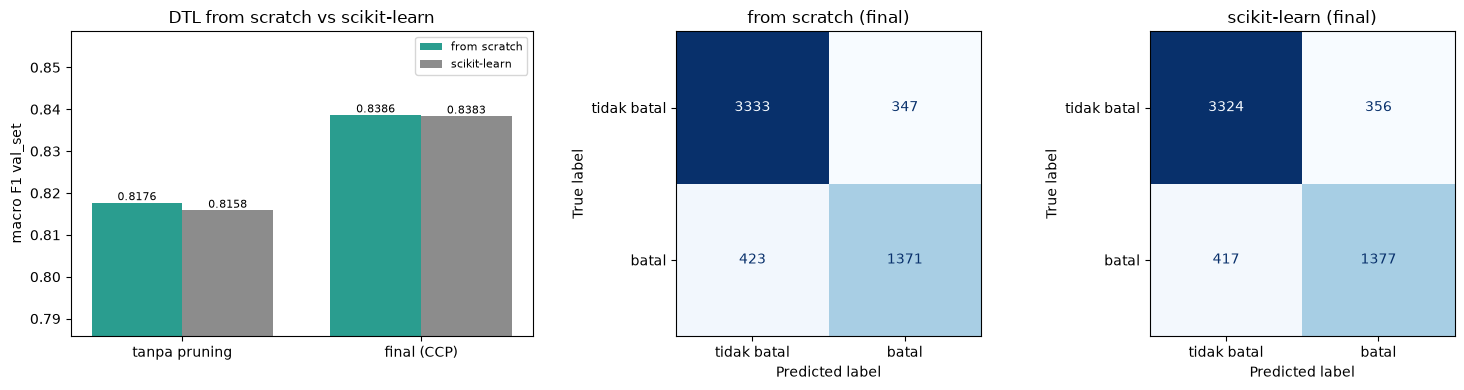

In [43]:
dtl_compare_rows, dtl_compare_pred = [], {}
for label, alpha in [('tanpa pruning', 0.0), ('final (CCP)', DTL_PARAMS['ccp_alpha'])]:
    params = {**DTL_PARAMS, 'ccp_alpha': alpha}
    for library in ('from scratch', 'scikit-learn'):
        start = perf_counter()
        if library == 'from scratch':
            model = DecisionTree(**params).fit(X_train_tree, y_train_array)
            fit_seconds = perf_counter() - start
            probability = model.predict_proba(X_val_tree)[:, 1]
            leaves, depth = model.n_leaves_, model.depth_
        else:
            model = DecisionTreeClassifier(criterion='gini', ccp_alpha=alpha,
                                           class_weight=params['class_weight'], random_state=CFG.SEED)
            model.fit(X_train_tree_sk, y_train_array)
            fit_seconds = perf_counter() - start
            probability = model.predict_proba(X_val_tree_sk)[:, 1]
            leaves, depth = model.get_n_leaves(), model.get_depth()
        predicted = (probability >= params['threshold']).astype(int)
        dtl_compare_pred[(label, library)] = predicted
        dtl_compare_rows.append({
            'kondisi': label, 'implementasi': library,
            'macro_f1': f1_score(y_valid, predicted, average='macro'),
            'accuracy': accuracy_score(y_valid, predicted),
            'f1_batal': f1_score(y_valid, predicted), 'daun': leaves, 'kedalaman': depth,
            'fit_detik': fit_seconds,
        })
dtl_compare = pd.DataFrame(dtl_compare_rows)
for label in ('tanpa pruning', 'final (CCP)'):
    agreement = np.mean(dtl_compare_pred[(label, 'from scratch')] == dtl_compare_pred[(label, 'scikit-learn')])
    dtl_compare.loc[dtl_compare['kondisi'] == label, 'kesamaan_prediksi'] = agreement
print(dtl_compare.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={'width_ratios': [1.3, 1, 1]})
width = .38
for offset, library, color in [(-width / 2, 'from scratch', '#2a9d8f'), (width / 2, 'scikit-learn', '#8c8c8c')]:
    values = dtl_compare[dtl_compare['implementasi'] == library]
    bars = axes[0].bar(np.arange(2) + offset, values['macro_f1'], width, label=library, color=color)
    axes[0].bar_label(bars, fmt='%.4f', fontsize=8)
axes[0].set_xticks(np.arange(2), ['tanpa pruning', 'final (CCP)'])
axes[0].set_ylim(dtl_compare['macro_f1'].min() - .03, dtl_compare['macro_f1'].max() + .02)
axes[0].set_ylabel('macro F1 val_set')
axes[0].set_title('DTL from scratch vs scikit-learn')
axes[0].legend(fontsize=8)
for ax, library in zip(axes[1:], ('from scratch', 'scikit-learn')):
    ConfusionMatrixDisplay.from_predictions(y_valid, dtl_compare_pred[('final (CCP)', library)],
                                            display_labels=['tidak batal', 'batal'], cmap='Blues',
                                            colorbar=False, ax=ax)
    ax.set_title(f'{library} (final)')
fig.tight_layout()
fig.savefig(CFG.OUTPUT_DIR / 'dtl_vs_sklearn.png', dpi=150, bbox_inches='tight')
plt.show()

**Analisis perbandingan dengan scikit-learn.** Dengan parameter yang sama, DTL kami dan `DecisionTreeClassifier` menghasilkan macro F1 yang hampir identik: 0,8386 vs 0,8383 pada pohon final dan 0,8176 vs 0,8158 tanpa pruning. Confusion matrix-nya juga hampir sama. Kesamaan prediksi pohon final 98,4%, dengan jumlah daun 201 vs 206 dan kedalaman yang sama (15). Pada pohon penuh kesamaannya 91,1%, karena pohon tanpa pruning sangat sensitif terhadap pilihan split yang nilainya seri. Pruning membuang split-split kecil itu sehingga kedua pohon menyatu.

Selisih yang tersisa berasal dari dua hal. Pertama, pohon kami membagi himpunan kategori secara optimal dalam satu split, sedangkan scikit-learn membutuhkan beberapa split one-hot untuk partisi yang sama. Kedua, scikit-learn memecah nilai seri secara acak. Pada data uji numerik tanpa kategori, kedua implementasi menghasilkan jumlah daun dan barisan $\alpha$ pruning yang persis sama. Ini menegaskan bahwa perhitungan Gini dan algoritma *weakest-link* kami sudah benar.

Perbedaan terbesar ada pada waktu: scikit-learn sekitar 0,17 detik dan implementasi kami sekitar 4,5 detik. scikit-learn ditulis dalam Cython dan mengurutkan data sekali di awal, sedangkan kami mengurutkan ulang di setiap simpul dengan NumPy. Waktu ini masih cukup cepat untuk menjalankan CV dengan 22 nilai $\alpha$ dalam beberapa menit, karena setiap fold hanya menumbuhkan satu pohon penuh.

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [44]:
saved_models = {}
for name, model in models.items():
    path = CFG.OUTPUT_DIR / (name.lower().replace(' ', '_') + '.pkl')
    model.save(path)
    restored = type(model).load(path)
    X_eval = model_inputs[model_factories[name][0]][1]
    np.testing.assert_array_equal(restored.predict(X_eval[:20]), predictions[name][:20])
    saved_models[name] = path
print('Model yang berhasil disimpan dan dimuat kembali:', len(saved_models))

Model yang berhasil disimpan dan dimuat kembali: 10


Setiap model disimpan lalu dimuat kembali sebelum hasil prediksinya dibandingkan. Pemeriksaan ini memastikan berkas model dapat dipakai ulang tanpa melatih ulang.

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [45]:
final_kind, final_factory = model_factories[best_name]
final_model = final_factory()
if final_kind == 'tree':
    final_prep = make_tree_preprocessor(**DTL_PREP_KWARGS).fit(train_df)
    X_full, X_submission = final_prep.transform(train_df), final_prep.transform(test_df)
else:
    prep_factory = {
        'numeric': make_numeric_preprocessor,
        'svm': make_svm_preprocessor,
        'nb': make_discrete_preprocessor,
        'knn': make_knn_preprocessor,
    }[final_kind]
    final_prep = prep_factory().fit(train_df)
    X_full, X_submission = final_prep.transform(train_df), final_prep.transform(test_df)
final_model.fit(X_full, train_df['is_canceled'].to_numpy())
final_model.save(CFG.OUTPUT_DIR / 'final_model.pkl')
with (CFG.OUTPUT_DIR / 'final_preprocessor.pkl').open('wb') as file:
    pickle.dump(final_prep, file)

restored_model = type(final_model).load(CFG.OUTPUT_DIR / 'final_model.pkl')
with (CFG.OUTPUT_DIR / 'final_preprocessor.pkl').open('rb') as file:
    restored_prep = pickle.load(file)
restored_test = (select_features(test_df) if restored_prep is None
                 else restored_prep.transform(test_df))
submission = pd.DataFrame({
    'id': test_ids,
    'is_canceled': restored_model.predict(restored_test).astype(int),
})
assert submission.columns.tolist() == ['id', 'is_canceled']
assert len(submission) == len(test_df)
assert submission['id'].equals(test_ids)
assert submission['is_canceled'].isin([0, 1]).all()
submission_path = CFG.OUTPUT_DIR / 'submission.csv'
submission.to_csv(submission_path, index=False)
print('Model akhir:', best_name)
print('Threshold:', getattr(final_model, 'threshold', None))
print('Proporsi prediksi batal:', round(submission['is_canceled'].mean(), 4))
print('Berkas submission:', submission_path, 'baris:', len(submission))

Model akhir: KNN
Threshold: 0.46
Proporsi prediksi batal: 0.3133
Berkas submission: ..\output\submission.csv baris: 6844


Submission dibuat dari model dengan macro F1 validasi tertinggi, yaitu KNN. Pipeline dan model dilatih ulang pada seluruh data berlabel, sedangkan data test hanya ditransformasi. Imputasi saudara untuk data test juga hanya merujuk ke data training. Model serta pipeline yang dimuat kembali menghasilkan prediksi akhir yang disimpan sebagai CSV.

In [46]:
# Submission tambahan khusus DTL. Konfigurasi dari CV di atas, model dilatih ulang pada seluruh data berlabel.
dtl_full_prep = make_tree_preprocessor(**DTL_PREP_KWARGS).fit(train_df)
dtl_full_model = DecisionTree(**DTL_PARAMS).fit(dtl_full_prep.transform(train_df), train_df['is_canceled'].to_numpy())
dtl_full_model.save(CFG.OUTPUT_DIR / 'dtl_final_model.pkl')
with (CFG.OUTPUT_DIR / 'dtl_final_preprocessor.pkl').open('wb') as file:
    pickle.dump(dtl_full_prep, file)
restored_dtl = DecisionTree.load(CFG.OUTPUT_DIR / 'dtl_final_model.pkl')
dtl_submission = pd.DataFrame({
    'id': test_ids,
    'is_canceled': restored_dtl.predict(dtl_full_prep.transform(test_df)).astype(int),
})
assert dtl_submission['id'].equals(test_ids) and dtl_submission['is_canceled'].isin([0, 1]).all()
dtl_submission.to_csv(CFG.OUTPUT_DIR / 'submission_dtl.csv', index=False)
print('DTL:', DTL_PARAMS, f'| {restored_dtl.n_leaves_} daun')
print('Proporsi prediksi batal:', round(dtl_submission['is_canceled'].mean(), 4))
print('Berkas:', CFG.OUTPUT_DIR / 'submission_dtl.csv', 'baris:', len(dtl_submission))

DTL: {'ccp_alpha': 0.00020000000000000004, 'class_weight': 'balanced', 'threshold': 0.72} | 204 daun
Proporsi prediksi batal: 0.2976
Berkas: ..\output\submission_dtl.csv baris: 6844


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [47]:
best_pred = predictions[best_name]
matrix = confusion_matrix(y_valid, best_pred, labels=[0, 1])
false_positive, false_negative = int(matrix[0, 1]), int(matrix[1, 0])
print('Confusion matrix:')
print(matrix)
print(classification_report(y_valid, best_pred, digits=4))
print('False positive:', false_positive, 'False negative:', false_negative)

error_rows = val_set[['booking_channel']].copy()
error_rows['error'] = best_pred != y_valid
print(error_rows.groupby('booking_channel')['error'].agg(
    total='size', error_rate='mean').round(4))

oof_error = (oof_knn >= BEST_THRESHOLD).astype(int) != y_all
missing_review = pd.DataFrame([
    {'column': column, 'missing_rows': int(mask.sum()),
     'error_when_missing': oof_error[mask].mean(), 'error_when_known': oof_error[~mask].mean()}
    for column in ['days_before_arrival', 'nightly_rate_idr', 'special_requests', 'meal_package']
    for mask in [train_df[column].isna().to_numpy()]
])
print(missing_review.round(4).to_string(index=False))
confidence = pd.qcut(pd.Series(np.abs(oof_knn - BEST_THRESHOLD)).rank(method='first'), 5,
                     labels=['paling ragu', '2', '3', '4', 'paling yakin'])
print(pd.Series(oof_error).groupby(confidence, observed=True).mean().rename('error_rate').round(4))

Confusion matrix:
[[3379  301]
 [ 358 1436]]
              precision    recall  f1-score   support

           0     0.9042    0.9182    0.9112      3680
           1     0.8267    0.8004    0.8134      1794

    accuracy                         0.8796      5474
   macro avg     0.8655    0.8593    0.8623      5474
weighted avg     0.8788    0.8796    0.8791      5474

False positive: 301 False negative: 358
                     total  error_rate
booking_channel                       
Airline                 16      0.1250
Complimentary           65      0.0000
Corporate              310      0.0742
Offline Agent         1633      0.0563
Online Travel Agent   3450      0.1571
             column  missing_rows  error_when_missing  error_when_known
days_before_arrival          1123              0.1567            0.1201
   nightly_rate_idr          2038              0.0962            0.1237
   special_requests          2500              0.1500            0.1188
       meal_package        

Confusion matrix memisahkan dua jenis prediksi yang salah. False positive berarti pemesanan diprediksi batal padahal sebenarnya tidak batal.

Kesalahan KNN paling banyak terjadi pada pemesanan kanal Online Travel Agent dan pada pemesanan yang `days_before_arrival`-nya kosong, karena fitur terpenting dan tanggal pemesanan ikut hilang. Imputasi saudara sudah menurunkan error kelompok ini, tetapi error-nya masih di atas baris lain. Error juga terkumpul pada prediksi dengan peluang dekat threshold, yaitu pemesanan yang tidak memiliki saudara jelas di data training. Sebaliknya, prediksi dengan peluang jauh dari threshold hampir selalu benar.

## Analisis Error DTL

Bagian ini menganalisis kesalahan DTL final pada `val_set` berdasarkan kanal pemesanan, nilai kosong, keyakinan daun, dan kesamaan kesalahannya dengan KNN.

In [48]:
dtl_val_proba = dtl_final.predict_proba(X_val_tree)[:, 1]
dtl_error = dtl_val_pred != y_valid
knn_error = predictions['KNN'] != y_valid


def group_f1(frame):
    return pd.Series({
        'baris': len(frame), 'proporsi_batal': frame['actual'].mean(),
        'error_rate': (frame['actual'] != frame['predicted']).mean(),
        'f1_batal': f1_score(frame['actual'], frame['predicted'], zero_division=0),
    })


dtl_frame = val_set[['booking_channel']].fillna('MISSING').assign(actual=y_valid, predicted=dtl_val_pred)
print('Per kanal pemesanan:')
print(dtl_frame.groupby('booking_channel')[['actual', 'predicted']].apply(group_f1).round(4))

missing_rows = []
for column in ['days_before_arrival', 'nightly_rate_idr', 'special_requests', 'meal_package',
               'room_category', 'num_children']:
    mask = val_set[column].isna().to_numpy()
    missing_rows.append({
        'kolom': column, 'baris_kosong': int(mask.sum()),
        'macro_f1_kosong': f1_score(y_valid[mask], dtl_val_pred[mask], average='macro'),
        'macro_f1_terisi': f1_score(y_valid[~mask], dtl_val_pred[~mask], average='macro'),
        'error_kosong': dtl_error[mask].mean(), 'error_terisi': dtl_error[~mask].mean(),
    })
print(pd.DataFrame(missing_rows).round(4).to_string(index=False))

# Keyakinan = jarak peluang daun ke threshold, dinormalisasi ke [0, 1].
threshold = DTL_PARAMS['threshold']
confidence = np.where(dtl_val_proba >= threshold, (dtl_val_proba - threshold) / (1 - threshold),
                      (threshold - dtl_val_proba) / threshold)
confidence = pd.cut(confidence, [0, .2, .4, .6, .8, 1.0], include_lowest=True)
print('Error terhadap keyakinan daun (jarak peluang ke threshold):')
print(pd.DataFrame({'baris': pd.Series(dtl_error).groupby(confidence, observed=True).size(),
                    'error_rate': pd.Series(dtl_error).groupby(confidence, observed=True).mean()}).round(4))

overlap = pd.crosstab(pd.Series(dtl_error, name='DTL salah'), pd.Series(knn_error, name='KNN salah'))
print('Kesalahan DTL vs KNN:')
print(overlap)

Per kanal pemesanan:
                      baris  proporsi_batal  error_rate  f1_batal
booking_channel                                                  
Airline                16.0          0.3125      0.2500    0.6667
Complimentary          65.0          0.0000      0.0154    0.0000
Corporate             310.0          0.1258      0.0871    0.4906
Offline Agent        1633.0          0.3037      0.0784    0.8664
Online Travel Agent  3450.0          0.3635      0.1768    0.7548
              kolom  baris_kosong  macro_f1_kosong  macro_f1_terisi  error_kosong  error_terisi
days_before_arrival           222           0.8287           0.8389        0.1351        0.1409
   nightly_rate_idr           393           0.8072           0.8410        0.1679        0.1386
   special_requests           506           0.8286           0.8383        0.1700        0.1377
       meal_package           356           0.8724           0.8361        0.1152        0.1424
      room_category           205    

**Analisis error DTL.**

- **Kanal pemesanan.** Kesalahan terbanyak ada di `Online Travel Agent` (error 17,7%, F1 batal 0,755), kanal terbesar dengan proporsi batal tertinggi (36%). Pemesanan lewat OTA mudah dibatalkan, dan fitur yang tersedia tidak membedakan tamu yang sungguh-sungguh dari yang sekadar memesan. `Offline Agent` jauh lebih mudah diprediksi (error 7,8%, F1 batal 0,866).
- **Nilai kosong.** Baris dengan `days_before_arrival` kosong kini memiliki error 13,5%, sedikit lebih rendah daripada baris yang terisi (14,1%), sehingga imputasi saudara berhasil menutup kehilangan fitur terpenting. Kekosongan yang paling merugikan adalah `nightly_rate_idr` (macro F1 0,807 vs 0,841) dan `special_requests` (0,829 vs 0,838). Keduanya fitur penting yang tidak diimputasi, sehingga barisnya mengikuti arah default yang lebih kasar.
- **Keyakinan daun.** Error sangat bergantung pada jarak peluang daun ke threshold. Pada 20% jarak terdekat, error 45,5%, hampir seperti menebak. Pada daun yang paling yakin, error hanya 3,9%. Lebih dari separuh baris validasi (2.966) jatuh di daun paling yakin, sehingga sebagian besar kesalahan terkumpul di daun yang campuran.
- **Dibandingkan KNN.** Dari 770 kesalahan DTL, 447 juga salah pada KNN. Kasus ini kemungkinan memang sulit dari fitur yang tersedia. Sisanya, 323 baris, hanya salah pada DTL: KNN mengenali pemesanan saudara dengan mencocokkan banyak atribut sekaligus, sedangkan pohon hanya melihat satu atribut per split. Sebaliknya, ada 212 baris yang benar pada DTL tetapi salah pada KNN.

**Kesimpulan DTL.** Setelah dioptimasi, macro F1 validasi DTL naik dari 0,768 menjadi 0,839, di atas SVM Gaussian (0,811) dan sedikit di bawah KNN akhir (0,862). Hasil ini setara dengan scikit-learn dengan parameter yang sama. Kenaikan terbesar berasal dari melatih dengan seluruh data (+0,050) dan cost-complexity pruning (+0,028 dibanding pohon penuh). Penyesuaian fitur dan threshold menambah sekitar 0,01.

## Cost-Sensitive Classification

False positive lebih mahal daripada false negative karena penginapan bisa *overbooked* jika pemesanan yang ternyata datang dianggap batal. Dengan asumsi false positive dua kali lebih mahal, biaya dihitung sebagai `2 × FP + FN`. Kami tidak melatih ulang model; yang diubah adalah threshold keputusan. Secara teori, threshold optimal untuk peluang yang terkalibrasi adalah `C_FP / (C_FP + C_FN) = 2/3` [Elkan, 2001]. Karena peluang voting KNN tidak terkalibrasi sempurna, threshold dipilih langsung dari biaya pada prediksi out-of-fold.

 threshold  false_positive  false_negative  cost  macro_f1
      0.40            2012            1505  5529    0.8562
      0.42            1865            1579  5309    0.8584
      0.44            1723            1654  5100    0.8603
      0.46            1582            1747  4911    0.8613
      0.48            1455            1853  4763    0.8612
      0.50            1359            1946  4664    0.8606
      0.52            1259            2063  4581    0.8589
      0.54            1179            2181  4539    0.8564
      0.56            1097            2290  4484    0.8543
      0.58            1009            2420  4438    0.8514
      0.60             924            2539  4387    0.8489
      0.62             842            2680  4364    0.8451
      0.64             784            2818  4386    0.8404
      0.66             700            2966  4366    0.8361
      0.68             618            3121  4357    0.8313
      0.70             561            3286  4408    0.82

Validasi:
                macro F1 (t=0.46)  biaya (t=0.68)
false_positive           301.0000        122.0000
false_negative           358.0000        638.0000
cost                     960.0000        882.0000
macro_f1                   0.8623          0.8281


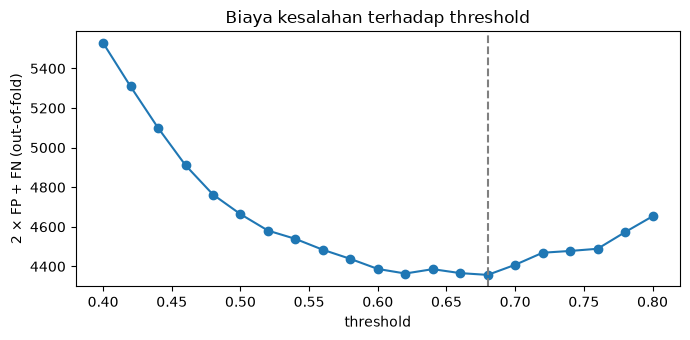

In [49]:
def booking_cost(y_true, predicted):
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {'false_positive': fp, 'false_negative': fn, 'cost': 2 * fp + fn,
            'macro_f1': f1_score(y_true, predicted, average='macro')}

cost_thresholds = np.round(np.arange(.40, .801, .02), 2)
cost_table = pd.DataFrame(
    [{'threshold': t, **booking_cost(y_all, (oof_knn >= t).astype(int))} for t in cost_thresholds])
COST_THRESHOLD = float(cost_table.loc[cost_table['cost'].idxmin(), 'threshold'])
print(cost_table.round(4).to_string(index=False))

cost_review = pd.DataFrame({
    f'macro F1 (t={BEST_THRESHOLD})': booking_cost(y_valid, (knn_final.predict_proba(X_val_knn)[:, 1] >= BEST_THRESHOLD).astype(int)),
    f'biaya (t={COST_THRESHOLD})': booking_cost(y_valid, (knn_final.predict_proba(X_val_knn)[:, 1] >= COST_THRESHOLD).astype(int)),
})
print('Validasi:')
print(cost_review.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(cost_table['threshold'], cost_table['cost'], marker='o')
ax.axvline(COST_THRESHOLD, linestyle='--', color='gray')
ax.set_xlabel('threshold')
ax.set_ylabel('2 × FP + FN (out-of-fold)')
ax.set_title('Biaya kesalahan terhadap threshold')
fig.tight_layout()
plt.show()

Biaya out-of-fold paling rendah ada pada threshold 0,68, sangat dekat dengan threshold teoretis 2/3. Pada data validasi, menaikkan threshold dari 0,46 ke 0,68 menurunkan false positive dari 301 menjadi 122 dan total biaya dari 960 menjadi 882. Konsekuensinya, false negative bertambah dan macro F1 turun dari 0,862 menjadi 0,828.

Jadi, penanganan berubah pada tahap keputusan, bukan pada model. Untuk kompetisi yang dinilai dengan macro F1, kami tetap memakai threshold 0,46. Jika penginapan lebih mementingkan biaya *overbooking*, model yang sama cukup dipakai dengan threshold sekitar 0,68 sehingga pemesanan baru dianggap batal jika keyakinan model cukup tinggi.

## References

- [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)
- [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)
- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)
- [KBinsDiscretizer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.KBinsDiscretizer.html)
- [Categorical Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html#categorical-naive-bayes)
- [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)
- J. C. Gower, "A general coefficient of similarity and some of its properties," *Biometrics*, vol. 27, no. 4, pp. 857–871, 1971. [doi:10.2307/2528823](https://doi.org/10.2307/2528823)
- G. E. A. P. A. Batista and M. C. Monard, "An analysis of four missing data treatment methods for supervised learning," *Applied Artificial Intelligence*, vol. 17, no. 5–6, pp. 519–533, 2003. [doi:10.1080/713827181](https://doi.org/10.1080/713827181)
- S. J. Wright, "Coordinate descent algorithms," *Mathematical Programming*, vol. 151, pp. 3–34, 2015. [doi:10.1007/s10107-015-0892-3](https://doi.org/10.1007/s10107-015-0892-3)
- C. Elkan, "The foundations of cost-sensitive learning," in *Proc. IJCAI*, 2001, pp. 973–978.
- N. Friedman, D. Geiger, and M. Goldszmidt, "Bayesian network classifiers," *Machine Learning*, vol. 29, no. 2–3, pp. 131–163, 1997. [doi:10.1023/A:1007465528199](https://doi.org/10.1023/A:1007465528199)
- C. K. Chow and C. N. Liu, "Approximating discrete probability distributions with dependence trees," *IEEE Transactions on Information Theory*, vol. 14, no. 3, pp. 462–467, 1968. [doi:10.1109/TIT.1968.1054142](https://doi.org/10.1109/TIT.1968.1054142)
- R. C. Prim, "Shortest connection networks and some generalizations," *Bell System Technical Journal*, vol. 36, no. 6, pp. 1389–1401, 1957. [doi:10.1002/j.1538-7305.1957.tb01515.x](https://doi.org/10.1002/j.1538-7305.1957.tb01515.x)
- L. Breiman, J. H. Friedman, R. A. Olshen, and C. J. Stone, *Classification and Regression Trees*. Wadsworth, 1984.
- T. Chen and C. Guestrin, "XGBoost: A scalable tree boosting system," in *Proc. 22nd ACM SIGKDD*, 2016, pp. 785–794. [doi:10.1145/2939672.2939785](https://doi.org/10.1145/2939672.2939785)
- [Decision Trees: Minimal Cost-Complexity Pruning (scikit-learn)](https://scikit-learn.org/stable/modules/tree.html#minimal-cost-complexity-pruning)
- A. Beck and M. Teboulle, "A fast iterative shrinkage-thresholding algorithm for linear inverse problems," *SIAM Journal on Imaging Sciences*, vol. 2, no. 1, pp. 183–202, 2009. [doi:10.1137/080716542](https://doi.org/10.1137/080716542)
- N. Parikh and S. Boyd, "Proximal algorithms," *Foundations and Trends in Optimization*, vol. 1, no. 3, pp. 127–239, 2014. [doi:10.1561/2400000003](https://doi.org/10.1561/2400000003)
- B. O'Donoghue and E. Candès, "Adaptive restart for accelerated gradient schemes," *Foundations of Computational Mathematics*, vol. 15, no. 3, pp. 715–732, 2015. [doi:10.1007/s10208-013-9150-3](https://doi.org/10.1007/s10208-013-9150-3)
- J. C. Platt, "Fast training of support vector machines using sequential minimal optimization," in *Advances in Kernel Methods: Support Vector Learning*. MIT Press, 1999, pp. 185–208.
- S. S. Keerthi, S. K. Shevade, C. Bhattacharyya, and K. R. K. Murthy, "Improvements to Platt's SMO algorithm for SVM classifier design," *Neural Computation*, vol. 13, no. 3, pp. 637–649, 2001. [doi:10.1162/089976601300014493](https://doi.org/10.1162/089976601300014493)
- R.-E. Fan, P.-H. Chen, and C.-J. Lin, "Working set selection using second order information for training support vector machines," *Journal of Machine Learning Research*, vol. 6, pp. 1889–1918, 2005. [Online](https://jmlr.org/papers/v6/fan05a.html)